# Beyond Words — Notebook 05: Conditions B and D (English + Hinglish task training)

**Research project:** Beyond Words — Cross-lingual Emotion and Sarcasm Analysis in Romanized Hinglish
**Notebook role:** Hinglish-adaptation conditions. Set `CONDITION` in Section 3: **B** = XLM-R, **D** = HingRoBERTa.
**Derived from:** `03_english_emotion_baseline.ipynb` (A) and `04_english_emotion_hingroberta_condC.ipynb` (C). Training, optimiser, scheduler, loss and evaluation code is carried over unchanged. Only the data and the selection rule differ, as listed below.

| Condition | Backbone | Task-training data |
|---|---|---|
| A | XLM-R | English only |
| **B** | **XLM-R** | **English + Hinglish (EmoSen, six classes)** |
| C | HingRoBERTa | English only |
| **D** | **HingRoBERTa** | **English + Hinglish (EmoSen, six classes)** |

## Label decision implemented here

`Others` is **excluded** from EmoSen. It is a residual class, not Neutral, and it is never mapped to Neutral in this notebook. The primary comparison uses the six shared classes: **anger, disgust, fear, joy, sadness, surprise**. A `Others → Neutral` run, if wanted, is a separate sensitivity experiment with its own results table.

## How the controlled design is kept

A and C use a 7-way classification head (the six classes plus Neutral) trained on the frozen English data. To keep B/D comparable with A/C, B/D keep **exactly the same head, label IDs and English training data**. Only the EmoSen six-class rows are added. Consequently:

- the English portion of the training set is byte-identical to A/C (checked against A's saved IDs);
- the Hinglish portion contains **no Neutral examples**. That is a limitation, not a bug;
- the six-class evaluation drops gold-Neutral examples and **masks the Neutral logit**. The same rule is applied to A and C from their saved logits, so all four conditions share one label space. A "strict" variant, where a Neutral prediction counts as an error, is reported as a secondary column.

## What differs from A/C (all documented in the metadata)

| Item | A / C | B / D |
|---|---|---|
| Training set | 39,257 English | 39,257 English + 7,694 EmoSen (about 16%) |
| Class weights | from English train | recomputed on the combined train set (same formula) |
| Optimiser steps | 3 epochs over the English set | 3 epochs over a set about 20% larger, so about 20% more steps |
| Checkpoint rule | best English validation macro-F1 (7-class) | best **pooled six-class** validation macro-F1 (English val + EmoSen val, Neutral masked). The English 7-class and Hinglish-only values are logged each epoch |

The selection rule differs because validation has to include Hinglish for B/D to adapt at all. Report this in the methods section.

## Test sets (each evaluated once per seed, after selection)

| Name | Content | Labels scored |
|---|---|---|
| `goemo_test` | GoEmotions test (English), identical to A/C | six classes primary; 7-class macro-F1 as supplementary |
| `emosen_test` | EmoSen test, Hinglish | six classes. **In-domain for B/D**, zero-shot for A/C |
| `hinemo_test` | HinEmo-9 gold Hinglish test (optional, if the prepared file exists) | five classes (no Disgust) |

`emosen_test` is the same source as the adaptation data, so B/D gain there reflects adaptation to that source, not general Hinglish transfer. `hinemo_test` is the held-out check and should carry more weight in the paper.


## Section 1 — Installation

Package versions are pinned to the ones used for Condition A (`transformers==4.48.3`, `tokenizers==0.21.0`). **Restart the runtime after this cell**, then continue from Section 2. Compare the versions printed in Section 8b with Condition A's `experiment_metadata.json`.


In [1]:
import subprocess, sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir",
         "transformers==4.48.3", "tokenizers==0.21.0", "sentencepiece",
         "accelerate>=1.2.0", "scikit-learn>=1.4.0", "seaborn>=0.13.0", "scipy>=1.12.0"],
        check=True,
    )
    print("Packages installed. RESTART THE RUNTIME NOW, then run from Section 2.")
else:
    print("Not in Colab: install transformers==4.48.3 tokenizers==0.21.0 sentencepiece "
          "accelerate scikit-learn seaborn scipy pandas numpy matplotlib in your environment.")


Packages installed. RESTART THE RUNTIME NOW, then run from Section 2.


## Section 2 — Imports

All imports are gathered in one cell so the notebook fails fast if a package is missing.  
`TOKENIZERS_PARALLELISM=false` suppresses a benign Hugging Face warning about forked processes.


In [4]:
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Standard library
import datetime
import json
import os
import platform
import random
import sys
import time
import warnings
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple

warnings.filterwarnings("ignore", category=UserWarning)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Scientific stack
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax as scipy_softmax

# scikit-learn
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

# Hugging Face Transformers
import transformers
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"Platform     : {platform.platform()}")
print(f"In Colab     : {IN_COLAB}")


Python       : 3.13.16
PyTorch      : 2.14.1+cu130
Transformers : 4.48.3
NumPy        : 2.4.6
Pandas       : 2.2.3
Platform     : Linux-6.6.159+-x86_64-with-glibc2.39
In Colab     : True


In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")   # needed to find Condition A outputs for the identity check

Mounted at /content/drive


## Section 3 — Condition, paths and data locations

Set `CONDITION` here: `"B"` (XLM-R) or `"D"` (HingRoBERTa). Outputs go to `outputs/hinglish_adapt_cond{B|D}` and `models/hinglish_adapt_cond{B|D}`, so Conditions A and C are never touched. The frozen `emosen_dedup_frozen.csv` must be uploaded to `data/processed/` through the Colab Files panel; EmoSen text is not put on Drive.

In [6]:
!cp -r /content/drive/MyDrive/Beyond-Words/data/processed /content/Beyond-Words/data/

In [7]:
# ── Which condition is this run? ────────────────────────────────────────────
CONDITION = "D"     # "B" = XLM-R + English + Hinglish   |   "D" = HingRoBERTa + English + Hinglish

_SPECS = {
    "B": {"model_name": "FacebookAI/xlm-roberta-base", "model_revision": None,  "short": "xlmr"},
    "D": {"model_name": "l3cube-pune/hing-roberta",    "model_revision": "f714c4bdce6b008a2fbb84193eee99e651c59e15", "short": "hingroberta"},
}
SPEC = _SPECS[CONDITION]

# ── Project paths ────────────────────────────────────────────────────────────
try:
    import google.colab  # noqa: F401
    PROJECT_ROOT = Path("/content/Beyond-Words")
except ImportError:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

TAG = f"hinglish_adapt_cond{CONDITION}"
DIRS = {
    "data_processed" : PROJECT_ROOT / "data" / "processed",
    "models_root"    : PROJECT_ROOT / "models"  / TAG,
    "out_predictions": PROJECT_ROOT / "outputs" / TAG / "predictions",
    "out_metrics"    : PROJECT_ROOT / "outputs" / TAG / "metrics",
    "out_logits"     : PROJECT_ROOT / "outputs" / TAG / "logits",
    "out_figures"    : PROJECT_ROOT / "outputs" / TAG / "figures",
    "out_logs"       : PROJECT_ROOT / "outputs" / TAG / "logs",
    "configs"        : PROJECT_ROOT / "configs",
}
for _p in DIRS.values():
    _p.mkdir(parents=True, exist_ok=True)

DATASET_PATH = DIRS["data_processed"] / "goemotions_ekman_dedup.csv"

# Restore the frozen dataset from Drive if it is not in this runtime (GoEmotions is public data).
if not DATASET_PATH.exists():
    try:
        import shutil
        from google.colab import drive
        drive.mount("/content/drive")
        _drive_csv = Path("/content/drive/MyDrive/Beyond-Words/data/processed/goemotions_ekman_dedup.csv")
        if _drive_csv.exists():
            shutil.copy2(_drive_csv, DATASET_PATH)
            print("Restored dataset from Drive:", _drive_csv)
    except Exception as _e:
        print("Drive restore skipped:", repr(_e)[:120])

EMOSEN_PATH = DIRS["data_processed"] / "emosen_dedup_frozen.csv"
HINEMO_PATH = DIRS["data_processed"] / "hinemo9_gold_hinglish_test.csv"   # optional, see Section 8d

print(f"Condition      : {CONDITION}  ({SPEC['model_name']})")
print(f"Project root   : {PROJECT_ROOT}")
print(f"GoEmotions CSV : {DATASET_PATH}  exists={DATASET_PATH.exists()}")
print(f"EmoSen CSV     : {EMOSEN_PATH}  exists={EMOSEN_PATH.exists()}")
print(f"HinEmo CSV     : {HINEMO_PATH}  exists={HINEMO_PATH.exists()}  (optional)")
if not DATASET_PATH.exists():
    raise FileNotFoundError("goemotions_ekman_dedup.csv not found. Copy it to data/processed/ first.")
if not EMOSEN_PATH.exists():
    raise FileNotFoundError(
        "emosen_dedup_frozen.csv not found. Upload it from your local machine through the Colab Files panel "
        "to data/processed/ (do NOT put EmoSen text on Drive)."
    )


Condition      : D  (l3cube-pune/hing-roberta)
Project root   : /content/Beyond-Words
GoEmotions CSV : /content/Beyond-Words/data/processed/goemotions_ekman_dedup.csv  exists=True
EmoSen CSV     : /content/Beyond-Words/data/processed/emosen_dedup_frozen.csv  exists=True
HinEmo CSV     : /content/Beyond-Words/data/processed/hinemo9_gold_hinglish_test.csv  exists=True  (optional)


## Section 4 — Experiment configuration

Identical to Condition A and C except the backbone, revision, names, and the two data/selection fields that describe the B/D design.

In [8]:
# ── Frozen label mapping (identical to A and C) ─────────────────────────────
LABEL_ORDER = ["anger", "disgust", "fear", "joy", "sadness", "surprise", "neutral"]
ID2LABEL    = {i: lbl for i, lbl in enumerate(LABEL_ORDER)}
LABEL2ID    = {lbl: i for i, lbl in enumerate(LABEL_ORDER)}
NUM_LABELS  = len(LABEL_ORDER)

CFG = {
    "model_name"          : SPEC["model_name"],
    "model_revision"      : SPEC["model_revision"],
    "num_labels"          : NUM_LABELS,
    "max_seq_len"         : 128,
    "dataset_path"        : str(DATASET_PATH),
    "hinglish_train_file" : EMOSEN_PATH.name,
    "hinglish_label_policy": "six classes; Others excluded; no Neutral from Hinglish",
    "num_epochs"          : 3,
    "train_batch_size"    : 16,
    "eval_batch_size"     : 32,
    "learning_rate"       : 2e-5,
    "weight_decay"        : 0.01,
    "warmup_ratio"        : 0.1,
    "grad_clip"           : 1.0,
    "grad_accum_steps"    : 1,
    "use_fp16"            : True,
    "use_class_weights"   : True,
    "seeds"               : [42, 123, 2026],
    "primary_metric"      : "macro_f1",
    "selection_rule"      : "pooled six-class validation macro-F1 (English val + EmoSen val, Neutral masked)",
    "experiment_name"     : f"{SPEC['short']}_english_plus_emosen6",
    "condition_label"     : CONDITION,
}
REV_KW = {"revision": CFG["model_revision"]} if CFG["model_revision"] else {}

config_path = DIRS["configs"] / f"hinglish_adapt_cond{CONDITION}_config.json"
with open(config_path, "w") as f:
    json.dump({**CFG, "label_order": LABEL_ORDER, "id2label": ID2LABEL, "label2id": LABEL2ID}, f, indent=2)
print("Experiment configuration:")
for k, v in CFG.items():
    print(f"  {k:<24} = {v}")
print(f"\nConfig saved: {config_path}")


Experiment configuration:
  model_name               = l3cube-pune/hing-roberta
  model_revision           = f714c4bdce6b008a2fbb84193eee99e651c59e15
  num_labels               = 7
  max_seq_len              = 128
  dataset_path             = /content/Beyond-Words/data/processed/goemotions_ekman_dedup.csv
  hinglish_train_file      = emosen_dedup_frozen.csv
  hinglish_label_policy    = six classes; Others excluded; no Neutral from Hinglish
  num_epochs               = 3
  train_batch_size         = 16
  eval_batch_size          = 32
  learning_rate            = 2e-05
  weight_decay             = 0.01
  warmup_ratio             = 0.1
  grad_clip                = 1.0
  grad_accum_steps         = 1
  use_fp16                 = True
  use_class_weights        = True
  seeds                    = [42, 123, 2026]
  primary_metric           = macro_f1
  selection_rule           = pooled six-class validation macro-F1 (English val + EmoSen val, Neutral masked)
  experiment_name          = hingro

## Section 4a — Label-space constants

Defined once, before any cell that uses them. `TEST_ALLOWED` lists the classes scored on each test set (Neutral is never scored; HinEmo-9 has no Disgust).

In [9]:
# ── Label-space constants (shared by training, evaluation and comparison) ─────
SIX_IDS  = (0, 1, 2, 3, 4, 5)       # anger, disgust, fear, joy, sadness, surprise (Neutral = 6 is never scored)
CORE_IDS = (0, 1, 3, 4)             # anger, disgust, joy, sadness: sensitivity set with enough support in EmoSen test
TEST_ALLOWED = {
    "goemo_test" : (0, 1, 2, 3, 4, 5),
    "emosen_test": (0, 1, 2, 3, 4, 5),
    "hinemo_test": (0, 2, 3, 4, 5),  # HinEmo-9 has no Disgust
}
# NOTE: "macro_f1_core" averages CORE_IDS that are present in the label space:
#       4 classes on goemo_test / emosen_test, 3 classes (anger, joy, sadness) on hinemo_test.


## Section 4b — Controlled-variable check

Condition C must use exactly Condition A's training settings. This cell compares the live `CFG` with A's frozen values and stops if anything differs. If you hit an out-of-memory error, halve `train_batch_size` and double `grad_accum_steps` so the effective batch stays 16, and record that deviation in the paper. Do the same for A if you re-run it.


In [10]:
A_FROZEN = {
    "num_labels"       : 7,
    "max_seq_len"      : 128,
    "num_epochs"       : 3,
    "eval_batch_size"  : 32,
    "learning_rate"    : 2e-5,
    "weight_decay"     : 0.01,
    "warmup_ratio"     : 0.1,
    "grad_clip"        : 1.0,
    "use_class_weights": True,
    "seeds"            : [42, 123, 2026],
    "primary_metric"   : "macro_f1",
}
_diff = {k: {"C": CFG[k], "A": v} for k, v in A_FROZEN.items() if CFG[k] != v}
_eff_batch = CFG["train_batch_size"] * CFG["grad_accum_steps"]

print("Effective train batch size:", _eff_batch, "(Condition A: 16)")
print("fp16 flag                 :", CFG["use_fp16"], "(Condition A: True)")
if _diff:
    raise RuntimeError(f"CFG differs from Condition A: {json.dumps(_diff, indent=2)}")
if _eff_batch != 16:
    raise RuntimeError(f"Effective batch {_eff_batch} != 16 (Condition A).")
print("CFG matches Condition A on every controlled hyper-parameter.")
print("Only the backbone, revision, experiment_name and condition_label differ.")


Effective train batch size: 16 (Condition A: 16)
fp16 flag                 : True (Condition A: True)
CFG matches Condition A on every controlled hyper-parameter.
Only the backbone, revision, experiment_name and condition_label differ.


## Section 5 — GPU and environment inspection

### Why check the GPU first?

Google Colab's free T4 GPU has ~15 GB VRAM. Training XLM-R-base at batch size 16 uses approximately 7–9 GB. If CUDA is unavailable, training falls back to CPU, which is ~50× slower — one epoch may take several hours instead of ~12 minutes.

### Mixed precision (FP16)

Instead of storing all weights and activations as 32-bit floats, FP16 uses 16-bit floats for most operations. This approximately:
- Halves VRAM consumption
- Speeds up computation via NVIDIA Tensor Cores

PyTorch's `torch.cuda.amp.autocast()` context manager handles FP16 automatically and falls back to FP32 for numerically sensitive operations (e.g., softmax).

### Recovery if CUDA out-of-memory (OOM)

If you encounter a CUDA OOM error:
1. Reduce `CFG["train_batch_size"]` from 16 → 8
2. Increase `CFG["grad_accum_steps"]` from 1 → 2 (keeps effective batch = 16)
3. Reduce `CFG["max_seq_len"]` from 128 → 96
4. Restart the runtime and re-run from the top

Do not silently change these settings mid-run — document any deviation.


In [11]:
print("=" * 60)
print("ENVIRONMENT INSPECTION")
print("=" * 60)

CUDA_AVAILABLE = torch.cuda.is_available()

if CUDA_AVAILABLE:
    DEVICE     = torch.device("cuda")
    gpu_name   = torch.cuda.get_device_name(0)
    gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"✅  CUDA available")
    print(f"   GPU model  : {gpu_name}")
    print(f"   VRAM total : {gpu_mem_gb:.1f} GB")
    print(f"   Mixed prec : {'FP16 enabled' if CFG['use_fp16'] else 'disabled (CFG override)'}")
else:
    DEVICE = torch.device("cpu")
    CFG["use_fp16"] = False   # FP16 requires CUDA
    print("⚠️  CUDA not available — training on CPU.")
    print("   FP16 disabled automatically.")
    print("   WARNING: CPU training is ~50× slower than T4 GPU.")

print(f"\n   Selected device  : {DEVICE}")
print(f"   PyTorch version  : {torch.__version__}")
print(f"   Transformers     : {transformers.__version__}")
print(f"   Python           : {sys.version.split()[0]}")
print("=" * 60)


ENVIRONMENT INSPECTION
✅  CUDA available
   GPU model  : Tesla T4
   VRAM total : 15.6 GB
   Mixed prec : FP16 enabled

   Selected device  : cuda
   PyTorch version  : 2.14.1+cu130
   Transformers     : 4.48.3
   Python           : 3.13.16


## Section 6 — Reproducibility utilities

### Why fix random seeds?

Neural network training involves many sources of randomness:
- **Weight initialisation** — the classification head starts from random values
- **Data-loading order** — the training DataLoader shuffles examples each epoch
- **Dropout** — randomly zeros activations during training
- **CUDA kernel non-determinism** — some GPU operations are non-deterministic by default

Fixing a seed makes **one specific run** reproducible. Different seeds will — and should — produce slightly different results. That is precisely why we run three seeds: to quantify variability rather than hide it behind a single lucky run.

### Performance note

`torch.backends.cudnn.deterministic = True` disables some highly-optimised but non-deterministic CUDA kernels. This can slow training by 10–30%. This trade-off is acceptable for research reproducibility.


In [12]:
def set_seed(seed: int) -> None:
    """Set all random seeds for reproducibility.

    Parameters
    ----------
    seed : int
        Seed value applied to Python, NumPy, PyTorch CPU, and PyTorch CUDA.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)
    print(f"🌱  Random seed set to {seed}")

# Set initial seed for dataset inspection (before training seeds)
set_seed(CFG["seeds"][0])


🌱  Random seed set to 42


## Section 7 — Dataset loading

The frozen dataset `goemotions_ekman_dedup.csv` was produced by notebook `01_dataset_exploration.ipynb`. We load it **read-only**.

### Confirmed CSV schema (inspected before writing this notebook)

| Column | Type | Description |
|---|---|---|
| `split` | str | `train`, `validation`, or `test` |
| `row_index` | int | Original row position in GoEmotions HF dataset |
| `example_id` | str | Unique Reddit comment identifier from GoEmotions |
| `text` | str | **Original text — used for training** |
| `source_labels` | str | Fine-grained GoEmotions label(s) before Ekman mapping |
| `mapped_label` | str | Seven-class Ekman label (our training target) |
| `keep` | bool | `True` for all rows (excluded examples were removed) |
| `mapping_reason` | str | Why this example was retained |
| `text_norm` | str | Lowercased/whitespace-normalised text (used for dedup checks only) |

### Why we use `text`, not `text_norm`

Lowercasing discards capitalisation signals that carry emotional information (e.g., "WHY THE FUCK" vs "why the fuck"). The tokeniser handles casing internally.

### Confirmed dataset counts (from preprocessing audit)

| Split | Count |
|---|---|
| Train | 39,257 |
| Validation | 4,930 |
| Test | 4,962 |
| **Total** | **49,149** |


In [13]:
print(f"Loading dataset: {DATASET_PATH}")
df = pd.read_csv(DATASET_PATH, dtype=str)   # dtype=str prevents silent type coercion

# ── Confirm required columns ──────────────────────────────────────────────
REQUIRED_COLS = ["split", "example_id", "text", "mapped_label", "keep", "text_norm"]
missing_cols  = [c for c in REQUIRED_COLS if c not in df.columns]
if missing_cols:
    raise ValueError(
        f"❌  Missing required columns: {missing_cols}\n"
        f"   Found columns: {df.columns.tolist()}"
    )

# Normalise string columns
df["mapped_label"] = df["mapped_label"].str.strip().str.lower()
df["split"]        = df["split"].str.strip().str.lower()

print(f"\nDataset shape : {df.shape}")
print(f"All columns   : {df.columns.tolist()}")
print(f"\nSplit counts:")
for split_name in ["train", "validation", "test"]:
    n = (df["split"] == split_name).sum()
    print(f"  {split_name:>12} : {n:>7,}")
print(f"  {'TOTAL':>12} : {len(df):>7,}")

print(f"\nSample rows:")
df.head(3)


Loading dataset: /content/Beyond-Words/data/processed/goemotions_ekman_dedup.csv

Dataset shape : (49149, 9)
All columns   : ['split', 'row_index', 'example_id', 'text', 'source_labels', 'mapped_label', 'keep', 'mapping_reason', 'text_norm']

Split counts:
         train :  39,257
    validation :   4,930
          test :   4,962
         TOTAL :  49,149

Sample rows:


,split,row_index,example_id,text,source_labels,mapped_label,keep,mapping_reason,text_norm
0,train,0,eebbqej,My favourite food is anything I didn't have to...,neutral,neutral,True,retained_neutral_only,my favourite food is anything i didn't have to...
1,train,1,ed00q6i,"Now if he does off himself, everyone will thin...",neutral,neutral,True,retained_neutral_only,"now if he does off himself, everyone will thin..."
2,train,2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,anger,anger,True,retained_single_ekman_group,why the fuck is bayless isoing


## Section 8 — Dataset integrity checks

Before any training, we validate the dataset against the documented preprocessing guarantees. If any check fails, training is halted — we do not silently fix or skip bad data.

### Checks performed

1. **Valid split names** — every row is `train`, `validation`, or `test`
2. **No cross-split example_id duplicates** — no `example_id` appears in multiple splits
3. **No text-level train/test leakage** — no normalised text exists in both train and test
4. **Valid labels** — every `mapped_label` is in the frozen seven-class ontology
5. **No null values** in critical columns
6. **Expected total count** — the documented 49,149 retained examples
7. **`keep` column is all True** — the CSV should contain only retained examples

### Why are these checks necessary?

The deduplication pipeline preserved train/test separation. We confirm that guarantee here rather than trusting it silently — a subtle data-leakage bug could make results appear artificially better and invalidate cross-condition comparisons.


In [14]:
print("=" * 60)
print("DATASET INTEGRITY CHECKS")
print("=" * 60)

errors        = []
warnings_list = []

# ── Check 1: Valid split names ─────────────────────────────────────────────
valid_splits   = {"train", "validation", "test"}
invalid_splits = set(df["split"].unique()) - valid_splits
if invalid_splits:
    errors.append(f"Invalid split names: {invalid_splits}")
else:
    print("✅  Check 1: All split names are valid")

# ── Check 2a: No cross-split example_id duplicates ───────────────────────
# (An example_id appearing in two different splits indicates deduplication
# failure — training could include an example seen in test.)
id_split_counts = df.groupby("example_id")["split"].nunique()
cross_split_ids = id_split_counts[id_split_counts > 1]
if len(cross_split_ids) > 0:
    errors.append(f"{len(cross_split_ids)} example_ids appear in multiple splits")
else:
    print("✅  Check 2a: No example_id appears in multiple splits")

# ── Check 2b: No duplicate example_ids within the same split ──────────────
# (Intra-split duplicates would inflate training or test counts and distort
# per-class metrics; they indicate a preprocessing bug.)
intra_dup = df.duplicated(subset="example_id", keep=False)
if intra_dup.any():
    n_dup_ids = df[intra_dup]["example_id"].nunique()
    errors.append(
        f"{n_dup_ids} example_ids appear more than once within their split "
        f"({intra_dup.sum()} total rows affected)"
    )
else:
    print("✅  Check 2b: Every example_id is globally unique")

# ── Check 3: No cross-split text-level leakage (all three pairs) ──────────
train_norms = set(df[df["split"] == "train"]["text_norm"].dropna())
val_norms   = set(df[df["split"] == "validation"]["text_norm"].dropna())
test_norms  = set(df[df["split"] == "test"]["text_norm"].dropna())

train_test_overlap = train_norms & test_norms
train_val_overlap  = train_norms & val_norms
val_test_overlap   = val_norms   & test_norms   # ← new: previously unchecked

if train_test_overlap:
    errors.append(f"Train/test text leakage: {len(train_test_overlap)} overlapping normalised texts")
else:
    print("✅  Check 3a: No train/test text leakage detected")

if train_val_overlap:
    # Treat as an error, consistent with how train/test and val/test overlaps are
    # handled. The frozen deduplication process is supposed to eliminate all
    # cross-split duplicates. Any overlap here indicates a preprocessing failure,
    # not an edge case to silently accept.
    errors.append(
        f"Train/validation text leakage: {len(train_val_overlap)} overlapping "
        "normalised texts. The deduplication pipeline should have removed these. "
        "Halt and investigate before training."
    )
else:
    print("✅  Check 3b: No train/validation text leakage detected")

if val_test_overlap:
    errors.append(
        f"Validation/test text leakage: {len(val_test_overlap)} overlapping normalised texts. "
        "This would corrupt test-set evaluation — halt and investigate."
    )
else:
    print("✅  Check 3c: No validation/test text leakage detected")

# ── Check 4: Valid labels ──────────────────────────────────────────────────
invalid_labels = set(df["mapped_label"].unique()) - set(LABEL_ORDER)
if invalid_labels:
    errors.append(f"Invalid labels found: {invalid_labels}")
else:
    print("✅  Check 4: All mapped_label values are in the seven-class ontology")

# ── Check 5: No null values in critical columns ────────────────────────────
null_counts = df[REQUIRED_COLS].isnull().sum()
critical_nulls = null_counts[null_counts > 0]
if len(critical_nulls) > 0:
    errors.append(f"Null values found:\n{critical_nulls.to_string()}")
else:
    print("✅  Check 5: No null values in critical columns")

# ── Check 6: Expected total count ─────────────────────────────────────────
EXPECTED_TOTAL = 49149
if len(df) != EXPECTED_TOTAL:
    warnings_list.append(
        f"Row count {len(df):,} ≠ expected {EXPECTED_TOTAL:,}. "
        "Review preprocessing audit before proceeding."
    )
    print(f"⚠️   Check 6: Row count mismatch (got {len(df):,}, expected {EXPECTED_TOTAL:,})")
else:
    print(f"✅  Check 6: Total row count matches expected ({EXPECTED_TOTAL:,})")

# ── Check 7: keep column is all True ──────────────────────────────────────
non_kept = (df["keep"].astype(str).str.strip().str.lower() != "true").sum()
if non_kept > 0:
    errors.append(f"{non_kept} rows have keep ≠ True — excluded examples should not be in this CSV")
else:
    print("✅  Check 7: All rows have keep=True (excluded examples correctly removed)")

# ── Report results ─────────────────────────────────────────────────────────
print()
for w in warnings_list:
    print(f"⚠️   WARNING: {w}")

if errors:
    print()
    for e in errors:
        print(f"❌  ERROR: {e}")
    raise RuntimeError(
        "\n\nDataset integrity checks FAILED. "
        "Do not proceed until the issues above are resolved. "
        "These checks protect research integrity."
    )

print("\n✅  All integrity checks passed. Dataset is safe to use for training.")


DATASET INTEGRITY CHECKS
✅  Check 1: All split names are valid
✅  Check 2a: No example_id appears in multiple splits
✅  Check 2b: Every example_id is globally unique
✅  Check 3a: No train/test text leakage detected
✅  Check 3b: No train/validation text leakage detected
✅  Check 3c: No validation/test text leakage detected
✅  Check 4: All mapped_label values are in the seven-class ontology
✅  Check 5: No null values in critical columns
✅  Check 6: Total row count matches expected (49,149)
✅  Check 7: All rows have keep=True (excluded examples correctly removed)


✅  All integrity checks passed. Dataset is safe to use for training.


## Section 9 — Label validation and split distribution analysis

### Why analyse class distributions before training?

GoEmotions is severely imbalanced:
- **Joy** and **Neutral** dominate because Reddit comments more often express positive sentiment or no clear emotion
- **Fear** and **Disgust** are rare (< 2% and < 2% of training data respectively)

A naive model that always predicts Joy or Neutral can achieve ~38% accuracy. This is why **accuracy is a misleading metric** for this task, and **macro-F1 is essential**.

We also verify that class distributions are roughly comparable across splits — if all Fear examples ended up in test but not validation, validation metrics would not reliably predict test performance.


In [15]:

print("=" * 60)
print("LABEL DISTRIBUTION ACROSS SPLITS")
print("=" * 60)

split_label_counts = {}
for split in ["train", "validation", "test"]:
    sdf    = df[df["split"] == split]
    counts = {lbl: int((sdf["mapped_label"] == lbl).sum()) for lbl in LABEL_ORDER}
    split_label_counts[split] = counts

# Print table
header = f"{'Emotion':<12}" + "".join(f"  {s:>12}" for s in ["Train", "Validation", "Test", "Total"])
print(header)
print("-" * len(header))
for lbl in LABEL_ORDER:
    tr = split_label_counts["train"][lbl]
    va = split_label_counts["validation"][lbl]
    te = split_label_counts["test"][lbl]
    tot = tr + va + te
    print(f"{lbl:<12}  {tr:>12,}  {va:>12,}  {te:>12,}  {tot:>12,}")

totals    = [sum(split_label_counts[s][l] for l in LABEL_ORDER) for s in ["train","validation","test"]]
grand_tot = sum(totals)
print("-" * len(header))
print(f"{'TOTAL':<12}  {totals[0]:>12,}  {totals[1]:>12,}  {totals[2]:>12,}  {grand_tot:>12,}")

train_counts  = split_label_counts["train"]
max_class     = max(train_counts, key=train_counts.get)
min_class     = min(train_counts, key=train_counts.get)
imb_ratio     = train_counts[max_class] / train_counts[min_class]
print(f"\n📊  Majority class (train) : {max_class} ({train_counts[max_class]:,})")
print(f"📊  Minority class (train) : {min_class} ({train_counts[min_class]:,})")
print(f"📊  Imbalance ratio        : {imb_ratio:.1f}×")
print(f"    Class-weighted loss is the primary planned configuration.")
print(f"    Compare with unweighted loss as a controlled ablation (CFG['use_class_weights']=False).")
print(f"    Do not assume weighting improves macro-F1 without evaluating both.")

# ── Per-split count audit against frozen preprocessing totals ─────────────
# These values come from notebook 01 and the deduplication audit.
# A mismatch that preserves the grand total (e.g., train 39258 / val 4929)
# would indicate that examples moved between splits — an error ordinary
# total-count checks would not catch.
FROZEN_SPLIT_COUNTS = {
    "train"      : 39257,
    "validation" : 4930,
    "test"       : 4962,
    "total"      : 49149,
}
print()
print("── Per-split count audit vs frozen preprocessing audit ──")
_split_errors = []
for split_name, expected in FROZEN_SPLIT_COUNTS.items():
    if split_name == "total":
        actual = len(df)
    else:
        actual = int((df["split"] == split_name).sum())
    match = "OK" if actual == expected else "MISMATCH"
    print(f"  {split_name:<12} : actual {actual:>7,}  |  expected {expected:>7,}  [{match}]")
    if actual != expected:
        _split_errors.append(f"{split_name}: got {actual}, expected {expected}")
if _split_errors:
    raise RuntimeError(
        "\n\nDataset split counts do not match the frozen preprocessing audit:\n"
        + "\n".join(f"  {e}" for e in _split_errors)
        + "\n\nDo not proceed. The dataset may have been altered. "
        "Restore goemotions_ekman_dedup.csv from the original preprocessing output."
    )
print("  All split counts match the frozen audit. Dataset is intact.")


LABEL DISTRIBUTION ACROSS SPLITS
Emotion              Train    Validation          Test         Total
--------------------------------------------------------------------
anger                4,280           555           572         5,407
disgust                493            61            76           630
fear                   537            72            80           689
joy                 15,032         1,928         1,858        18,818
sadness              2,313           266           283         2,862
surprise             3,840           457           488         4,785
neutral             12,762         1,591         1,605        15,958
--------------------------------------------------------------------
TOTAL               39,257         4,930         4,962        49,149

📊  Majority class (train) : joy (15,032)
📊  Minority class (train) : disgust (493)
📊  Imbalance ratio        : 30.5×
    Class-weighted loss is the primary planned configuration.
    Compare with unweighted 

## Section 8b — Cross-condition identity checks

Three checks that tie Condition C to Condition A:

1. **Dataset fingerprint.** SHA-256 of the CSV, stored in the experiment metadata.
2. **Split identity.** The validation and test `example_id` sequences must equal the ones in Condition A's saved logits files, in the same order. This proves both conditions are scored on the same examples.
3. **Software versions.** Current versions are printed next to the ones recorded for Condition A.

Checks 2 and 3 need Condition A's outputs. They are looked up in `outputs/english_emotion` and in `MyDrive/Beyond-Words/outputs/english_emotion`. If neither exists the checks are skipped with a warning and Section 23 cannot run later.


In [16]:

import hashlib

DATASET_SHA256 = hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
print("Dataset SHA-256:", DATASET_SHA256)

A_OUTPUT_ROOT = None
for _cand in [
    PROJECT_ROOT / "outputs" / "english_emotion",
    Path("/content/drive/MyDrive/Beyond-Words/outputs/english_emotion"),
]:
    if (_cand / "logits").exists():
        A_OUTPUT_ROOT = _cand
        break
print("Condition A outputs:", A_OUTPUT_ROOT if A_OUTPUT_ROOT else "NOT FOUND")

if A_OUTPUT_ROOT is not None:
    _a_tag = "xlmr_english_ekman7_condA"
    _a_seed = CFG["seeds"][0]

    # Test split
    _a_test = pd.read_csv(A_OUTPUT_ROOT / "logits" / f"test_logits_{_a_tag}_seed{_a_seed}.csv",
                          dtype={"example_id": str}, usecols=["example_id", "true_label"])
    _c_test = df[df["split"] == "test"][["example_id", "mapped_label"]].reset_index(drop=True)
    assert _a_test["example_id"].tolist() == _c_test["example_id"].tolist(), \
        "TEST example_id sequence differs from Condition A."
    assert _a_test["true_label"].tolist() == _c_test["mapped_label"].tolist(), \
        "TEST labels differ from Condition A."
    print(f"Test split identical to Condition A ({len(_c_test):,} examples, same order).")

    # Validation split (any saved best-epoch file has the same ids)
    _a_val_files = sorted((A_OUTPUT_ROOT / "logits").glob(f"val_logits_{_a_tag}_seed{_a_seed}_best_epoch*.csv"))
    if _a_val_files:
        _a_val = pd.read_csv(_a_val_files[0], dtype={"example_id": str}, usecols=["example_id", "true_label"])
        _c_val = df[df["split"] == "validation"][["example_id", "mapped_label"]].reset_index(drop=True)
        assert _a_val["example_id"].tolist() == _c_val["example_id"].tolist(), \
            "VALIDATION example_id sequence differs from Condition A."
        assert _a_val["true_label"].tolist() == _c_val["mapped_label"].tolist(), \
            "VALIDATION labels differ from Condition A."
        print(f"Validation split identical to Condition A ({len(_c_val):,} examples, same order).")
    else:
        print("WARNING: no Condition A validation logits found; validation identity not checked.")

    _a_meta_path = A_OUTPUT_ROOT / "metrics" / "experiment_metadata.json"
    if _a_meta_path.exists():
        _a_sw = json.loads(_a_meta_path.read_text()).get("software", {})
        _now = {"pytorch": torch.__version__, "transformers": transformers.__version__,
                "numpy": np.__version__, "pandas": pd.__version__}
        print("\nSoftware versions (Condition A recorded vs now):")
        for k, v in _now.items():
            a_v = str(_a_sw.get(k, "n/a"))
            flag = "" if a_v.split("+")[0] == str(v).split("+")[0] else "   <-- DIFFERS"
            print(f"  {k:<13} A: {a_v:<14} C: {v}{flag}")
else:
    print("\nWARNING: Condition A outputs not found. Split identity NOT verified.")
    print("Mount Drive or copy A's outputs/english_emotion folder, then re-run this cell.")


Dataset SHA-256: 95fa0632a30a54b8210a6bdc0f607810951061b1263fe2d97ca3dc0b5911ac9b
Condition A outputs: /content/drive/MyDrive/Beyond-Words/outputs/english_emotion
Test split identical to Condition A (4,962 examples, same order).
Validation split identical to Condition A (4,930 examples, same order).

Software versions (Condition A recorded vs now):
  pytorch       A: 2.15.0+cu132   C: 2.14.1+cu130   <-- DIFFERS
  transformers  A: 4.48.3         C: 4.48.3
  numpy         A: 2.5.4          C: 2.4.6   <-- DIFFERS
  pandas        A: 3.1.1          C: 2.2.3   <-- DIFFERS


## Section 8c — Load EmoSen (frozen, deduplicated) and build the adaptation data

The loader validates the CSV against the frozen dedup audit (per-split, per-class counts, and the number of `Others` rows). If the numbers differ, it stops: you may have the wrong file. It then drops `Others`.

Access gate: `EMOSEN_PERMISSION_CONFIRMED` must be set to `True` by you, and only with written confirmation that this processing is covered.


In [18]:
import hashlib
# ── EmoSen (frozen, deduplicated) and optional HinEmo-9 gold loaders ─────────
EMOSEN_PERMISSION_CONFIRMED = True   # set True ONLY with written confirmation covering this processing

SIX_NAMES = LABEL_ORDER[:6]
EXPECTED_EMOSEN_SIX = {   # retained rows per split after dedup, Others excluded (from the frozen audit)
    "train"     : {"anger": 2037, "disgust": 1016, "fear": 56, "joy": 3712, "sadness": 823, "surprise": 50},
    "validation": {"anger": 601,  "disgust": 55,   "fear": 4,  "joy": 961,  "sadness": 299, "surprise": 6},
    "test"      : {"anger": 677,  "disgust": 105,  "fear": 13, "joy": 1004, "sadness": 121, "surprise": 7},
}
EXPECTED_EMOSEN_OTHERS = {"train": 5828, "validation": 1036, "test": 1060}

def load_emosen_six(path):
    """Load the frozen EmoSen CSV, validate it against the frozen audit, drop Others, return six-class rows."""
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    pick = lambda opts: next((c for c in opts if c in raw.columns), None)
    c_split, c_id = pick(["split"]), pick(["id", "example_id"])
    c_text, c_lab = pick(["tweet_fixed", "text"]), pick(["emotion", "mapped_label", "label"])
    if None in (c_split, c_id, c_text, c_lab):
        raise ValueError(f"EmoSen CSV needs split/id/tweet_fixed/emotion columns; found {list(raw.columns)}")
    d = pd.DataFrame({
        "split"  : raw[c_split].str.strip().str.lower().replace({"val": "validation", "dev": "validation"}),
        "id"     : raw[c_id].str.strip(),
        "text"   : raw[c_text],
        "emotion": raw[c_lab].str.strip().str.lower(),
    })
    if set(d["split"]) != {"train", "validation", "test"}:
        raise ValueError(f"Unexpected EmoSen splits: {sorted(set(d['split']))}")
    if d.duplicated(["split", "id"]).any():
        raise ValueError("Duplicate (split, id) rows in the EmoSen CSV.")
    unknown = set(d["emotion"]) - set(SIX_NAMES) - {"others"}
    if unknown:
        raise ValueError(f"Unexpected EmoSen emotion labels: {sorted(unknown)}")
    if (d["text"].str.strip() == "").any():
        raise ValueError("Empty EmoSen text found.")

    others = d[d["emotion"] == "others"].groupby("split").size().to_dict()
    six    = d[d["emotion"] != "others"].copy()
    got    = {s: six[six["split"] == s].groupby("emotion").size().to_dict() for s in EXPECTED_EMOSEN_SIX}
    problems = []
    for s, exp in EXPECTED_EMOSEN_SIX.items():
        if got[s] != exp:
            problems.append(f"{s}: got {got[s]}, expected {exp}")
        if others.get(s, 0) != EXPECTED_EMOSEN_OTHERS[s]:
            problems.append(f"{s} Others: got {others.get(s, 0)}, expected {EXPECTED_EMOSEN_OTHERS[s]}")
    if problems:
        raise RuntimeError("EmoSen CSV does not match the frozen dedup audit:\n  " + "\n  ".join(problems))

    six["label_id"] = six["emotion"].map(LABEL2ID)
    return six.reset_index(drop=True), others

EXPECTED_HINEMO_RAW     = 393
EXPECTED_HINEMO_KEPT    = {"anger": 35, "fear": 49, "joy": 38, "sadness": 26, "surprise": 122}
EXPECTED_HINEMO_DROPPED = {"love": 41, "devotion": 31, "neutral": 26, "nostalgia": 25}

def load_hinemo_optional(path, strict=True):
    """Optional prepared HinEmo-9 gold Hinglish test file: columns id,text,label.
    Validates the raw file (393 rows, unique ids, non-empty text, expected label counts) before filtering to the
    five shared classes, so an accidentally replaced CSV cannot silently change the test set."""
    if not Path(path).exists():
        return None, {}
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    for c in ("id", "text", "label"):
        if c not in raw.columns:
            raise ValueError(f"HinEmo file needs columns id,text,label; found {list(raw.columns)}")
    lab = raw["label"].str.strip().str.lower()
    if strict:
        problems = []
        if len(raw) != EXPECTED_HINEMO_RAW:
            problems.append(f"rows: got {len(raw)}, expected {EXPECTED_HINEMO_RAW}")
        if raw["id"].str.strip().duplicated().any():
            problems.append("duplicate ids")
        if (raw["text"].str.strip() == "").any():
            problems.append("empty text")
        got = lab.value_counts().to_dict()
        want = {**EXPECTED_HINEMO_KEPT, **EXPECTED_HINEMO_DROPPED}
        if got != want:
            problems.append(f"label counts: got {got}, expected {want}")
        if problems:
            raise RuntimeError("HinEmo-9 CSV does not match the audited gold test split:\n  " + "\n  ".join(problems))
    dropped = lab[~lab.isin(SIX_NAMES)].value_counts().to_dict()
    d = raw[lab.isin(SIX_NAMES)].copy()
    d["label_id"] = lab[lab.isin(SIX_NAMES)].map(LABEL2ID)
    d = d.rename(columns={"id": "example_id"})[["example_id", "text", "label_id"]].reset_index(drop=True)
    return d, dropped


if not EMOSEN_PERMISSION_CONFIRMED:
    raise PermissionError(
        "EmoSen use is gated. Set EMOSEN_PERMISSION_CONFIRMED = True in this cell only after you hold written "
        "confirmation that this processing (Colab, non-commercial research) is allowed."
    )

hi_six, hi_others = load_emosen_six(EMOSEN_PATH)
EMOSEN_SHA256 = hashlib.sha256(EMOSEN_PATH.read_bytes()).hexdigest()
print("EmoSen file SHA-256:", EMOSEN_SHA256)
print("Others rows dropped :", hi_others)
print("\nEmoSen six-class rows kept:")
print(pd.crosstab(hi_six["split"], hi_six["emotion"]).reindex(
    index=["train", "validation", "test"], columns=SIX_NAMES))

# Exact-text leakage guard: Hinglish splits must not overlap each other or the English data
_norm = lambda s: " ".join(str(s).lower().split())
_hi_sets = {s: {_norm(t) for t in hi_six.loc[hi_six["split"] == s, "text"]} for s in ("train", "validation", "test")}
assert not (_hi_sets["train"] & _hi_sets["test"]) and not (_hi_sets["train"] & _hi_sets["validation"]) \
    and not (_hi_sets["validation"] & _hi_sets["test"]), "Hinglish splits share normalised texts."
_en_all = {_norm(t) for t in df["text"]}
_hi_vs_en = sum(len(v & _en_all) for v in _hi_sets.values())
print(f"Exact normalised overlaps between Hinglish and English data: {_hi_vs_en}")


EmoSen file SHA-256: 57bffcf415be63823bdc6a5fcd2a7141e743c53f789dab3acb2a918289534b0d
Others rows dropped : {'test': 1060, 'train': 5828, 'validation': 1036}

EmoSen six-class rows kept:
emotion     anger  disgust  fear   joy  sadness  surprise
split                                                    
train        2037     1016    56  3712      823        50
validation    601       55     4   961      299         6
test          677      105    13  1004      121         7
Exact normalised overlaps between Hinglish and English data: 0


## Section 8d — Combined training data and test sets

Training and validation are the English split plus the EmoSen six-class split of the same name; example IDs are prefixed `en:` / `hi:` internally and the prefix is stripped from the saved test logits. Test sets stay separate. `hinemo_test` is optional: it needs a prepared file `data/processed/hinemo9_gold_hinglish_test.csv` with columns `id,text,label` (HinEmo-9 gold Hinglish test; labels outside the shared classes are dropped here and counted).

In [19]:
def _en_part(split):
    d = df[df["split"] == split]
    return pd.DataFrame({"example_id": "en:" + d["example_id"].astype(str), "text": d["text"].values,
                         "label_id": d["mapped_label"].map(LABEL2ID).values, "domain": "en"})

def _hi_part(split):
    d = hi_six[hi_six["split"] == split]
    return pd.DataFrame({"example_id": "hi:" + d["id"].astype(str), "text": d["text"].values,
                         "label_id": d["label_id"].values, "domain": "hi"})

DF_TRAIN = pd.concat([_en_part("train"),      _hi_part("train")],      ignore_index=True)
DF_VAL   = pd.concat([_en_part("validation"), _hi_part("validation")], ignore_index=True)

_goemo_test = df[df["split"] == "test"]
TEST_SETS = {
    "goemo_test" : pd.DataFrame({"example_id": _goemo_test["example_id"].astype(str).values,
                                 "text": _goemo_test["text"].values,
                                 "label_id": _goemo_test["mapped_label"].map(LABEL2ID).values}),
    "emosen_test": pd.DataFrame({"example_id": hi_six.loc[hi_six["split"] == "test", "id"].astype(str).values,
                                 "text": hi_six.loc[hi_six["split"] == "test", "text"].values,
                                 "label_id": hi_six.loc[hi_six["split"] == "test", "label_id"].values}),
}
_hn, _hn_dropped = load_hinemo_optional(HINEMO_PATH)
if _hn is not None:
    TEST_SETS["hinemo_test"] = _hn
    print(f"HinEmo-9 gold test loaded: {len(_hn)} rows; labels outside the shared classes dropped: {_hn_dropped}")
else:
    print("HinEmo-9 gold test file not found: skipping hinemo_test (optional).")

print("\nTraining composition (rows):")
_comp = pd.crosstab(DF_TRAIN["domain"], DF_TRAIN["label_id"].map(ID2LABEL)).reindex(columns=LABEL_ORDER, fill_value=0)
_comp["total"] = _comp.sum(axis=1)
print(_comp)
print(f"\nTrain: {len(DF_TRAIN):,} rows  ({(DF_TRAIN['domain']=='hi').mean():.1%} Hinglish)")
print(f"Validation: {len(DF_VAL):,} rows  ({(DF_VAL['domain']=='hi').mean():.1%} Hinglish)")
for _n, _d in TEST_SETS.items():
    print(f"Test set {_n:<12}: {len(_d):,} rows, allowed classes {[ID2LABEL[i] for i in TEST_ALLOWED[_n]]}")

assert len(DF_TRAIN[DF_TRAIN.domain == "en"]) == 39257, "English train must equal A/C (39,257)."
assert len(TEST_SETS["goemo_test"]) == 4962
assert DF_TRAIN["example_id"].is_unique and DF_VAL["example_id"].is_unique
assert not (DF_TRAIN["label_id"].eq(LABEL2ID["neutral"]) & DF_TRAIN["domain"].eq("hi")).any()
print("\nAssertions passed: English train identical in size to A/C, no Hinglish Neutral rows.")


HinEmo-9 gold test loaded: 270 rows; labels outside the shared classes dropped: {'love': 41, 'devotion': 31, 'neutral': 26, 'nostalgia': 25}

Training composition (rows):
label_id  anger  disgust  fear    joy  sadness  surprise  neutral  total
domain                                                                  
en         4280      493   537  15032     2313      3840    12762  39257
hi         2037     1016    56   3712      823        50        0   7694

Train: 46,951 rows  (16.4% Hinglish)
Validation: 6,856 rows  (28.1% Hinglish)
Test set goemo_test  : 4,962 rows, allowed classes ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Test set emosen_test : 1,927 rows, allowed classes ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Test set hinemo_test : 270 rows, allowed classes ['anger', 'fear', 'joy', 'sadness', 'surprise']

Assertions passed: English train identical in size to A/C, no Hinglish Neutral rows.


## Section 10 — Tokeniser loading

### What is a tokeniser?

A tokeniser converts raw text into a sequence of integer **token IDs** that the model can process. XLM-RoBERTa uses **SentencePiece** tokenisation with a vocabulary of 250,002 tokens covering 100 languages.

The tokeniser also produces:
- **`input_ids`** — the integer token IDs (including special tokens `<s>` and `</s>`)
- **`attention_mask`** — 1 for real tokens, 0 for padding; the model ignores padded positions

### Why preserve original text (not `text_norm`)?

XLM-RoBERTa's vocabulary includes both cased and uncased tokens. Lowercasing discards capitalisation signals that carry emotional weight ("WHY" vs "why"). We use the original `text` column, not the normalised `text_norm`.


In [20]:
print(f"Loading tokeniser: {CFG['model_name']}")
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"], **REV_KW)

print(f"Tokeniser class  : {type(tokenizer).__name__}")
print(f"Vocabulary size  : {tokenizer.vocab_size:,}")
print(f"Model max length : {tokenizer.model_max_length}")
print(f"Config max_seq_len: {CFG['max_seq_len']}")

# Sanity check on a sample with emotional content
sample_text   = "WHY THE FUCK IS THIS HAPPENING?! 😡"
sample_tokens = tokenizer(sample_text, return_tensors="pt")
token_strings = tokenizer.convert_ids_to_tokens(sample_tokens["input_ids"][0].tolist())
print(f"\nSample            : {sample_text!r}")
print(f"Token ids shape   : {sample_tokens['input_ids'].shape}")
print(f"Tokens            : {token_strings}")
print("\n✅  Tokeniser loaded successfully.")


Loading tokeniser: l3cube-pune/hing-roberta


tokenizer_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Tokeniser class  : XLMRobertaTokenizerFast
Vocabulary size  : 250,002
Model max length : 512
Config max_seq_len: 128

Sample            : 'WHY THE FUCK IS THIS HAPPENING?! 😡'
Token ids shape   : torch.Size([1, 17])
Tokens            : ['<s>', '▁W', 'HY', '▁THE', '▁FU', 'CK', '▁IS', '▁TH', 'IS', '▁H', 'APP', 'E', 'NING', '?!', '▁', '😡', '</s>']

✅  Tokeniser loaded successfully.


## Section 10b — Backbone and tokenizer verification (C vs XLM-R)

Before training, confirm what HingRoBERTa actually is:

- the architecture matches XLM-R base, so the classification head and optimiser settings are directly comparable;
- how often its tokenizer produces exactly the same token ids as XLM-R's on this corpus. If it is 100%, the two conditions differ only in backbone weights. If not, tokenisation is a second difference and must be reported;
- the exact Hub commit that was loaded.


In [21]:
from transformers import AutoConfig

_cfg_h = AutoConfig.from_pretrained(CFG["model_name"], revision=CFG["model_revision"])
_cfg_x = AutoConfig.from_pretrained("FacebookAI/xlm-roberta-base")

_keys = ["model_type", "num_hidden_layers", "hidden_size", "num_attention_heads",
         "intermediate_size", "vocab_size", "max_position_embeddings", "type_vocab_size"]
print(f"{'field':<26}{'HingRoBERTa':>16}{'XLM-R base':>16}")
for k in _keys:
    a, b = getattr(_cfg_h, k, None), getattr(_cfg_x, k, None)
    print(f"{k:<26}{str(a):>16}{str(b):>16}{'' if a == b else '   <-- differs'}")

assert _cfg_h.hidden_size == _cfg_x.hidden_size and _cfg_h.num_hidden_layers == _cfg_x.num_hidden_layers, \
    "Backbone dimensions differ from XLM-R base: classification heads are not directly comparable."

_tok_x = AutoTokenizer.from_pretrained("FacebookAI/xlm-roberta-base")
_texts = df["text"].tolist()

def _encode_all(tok, texts, bs=2048):
    out = []
    for i in range(0, len(texts), bs):
        out.extend(tok(texts[i:i + bs], add_special_tokens=True,
                       truncation=False, padding=False)["input_ids"])
    return out

_ids_h = _encode_all(tokenizer, _texts)
_ids_x = _encode_all(_tok_x, _texts)
TOK_SAME_FRAC = float(np.mean([a == b for a, b in zip(_ids_h, _ids_x)]))
print(f"\nExamples with identical token ids (HingRoBERTa vs XLM-R tokenizer): {TOK_SAME_FRAC:.4%}")
print(f"Tokenizer vocab sizes: HingRoBERTa {len(tokenizer):,}  |  XLM-R {len(_tok_x):,}")
if TOK_SAME_FRAC < 1.0:
    print("NOTE: tokenisation differs from XLM-R. Report this as a second difference between A and C.")

RESOLVED_SHA = None
try:
    from huggingface_hub import HfApi
    RESOLVED_SHA = HfApi().model_info(CFG["model_name"], revision=CFG["model_revision"]).sha
    print("\nResolved Hub commit:", RESOLVED_SHA)
except Exception as _e:
    print("\nCould not resolve the Hub commit hash:", repr(_e)[:200])
del _tok_x, _ids_h, _ids_x


config.json:   0%|          | 0.00/750 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

field                          HingRoBERTa      XLM-R base
model_type                     xlm-roberta     xlm-roberta
num_hidden_layers                       12              12
hidden_size                            768             768
num_attention_heads                     12              12
intermediate_size                     3072            3072
vocab_size                          250002          250002
max_position_embeddings                514             514
type_vocab_size                          1               1


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


Examples with identical token ids (HingRoBERTa vs XLM-R tokenizer): 100.0000%
Tokenizer vocab sizes: HingRoBERTa 250,002  |  XLM-R 250,002

Resolved Hub commit: f714c4bdce6b008a2fbb84193eee99e651c59e15


## Section 10b — Model forward-pass sanity check

### Why do this before training?

Loading a model and running it on two synthetic sentences takes a few seconds and
costs no GPU budget worth mentioning. It catches four classes of problem before we
commit to a 35-45 minute training run:

1. **Network download failure** — the checkpoint or config cannot be fetched from
   Hugging Face Hub.
2. **Shape mismatch** — if `NUM_LABELS`, `id2label`, or `label2id` are inconsistent,
   the classification head will have the wrong output dimension and the assertion
   `sample_logits.shape == (2, NUM_LABELS)` will fail.
3. **Non-finite logits** — `NaN` or `Inf` in the first forward pass indicates a
   configuration or precision issue, not a training problem.
4. **Device mismatch** — if inputs are on CPU but the model is on GPU (or vice versa),
   PyTorch raises an error here rather than deep inside the training loop.

The sanity model is deleted immediately after the check so GPU memory is fully
available for training.

In [22]:
# ── Model forward-pass sanity check ──────────────────────────────────────
# Temporarily load the model to verify architecture before training.
# This is NOT the training model — it is deleted as soon as the check passes.
print("=" * 60)
print("MODEL FORWARD-PASS SANITY CHECK")
print("=" * 60)

print(f"  Loading: {CFG['model_name']}")
_sanity_model = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"],
    **REV_KW,
    num_labels = NUM_LABELS,
    id2label   = ID2LABEL,
    label2id   = LABEL2ID,
).to(DEVICE)

# Two sentences chosen to exercise both positive and negative emotion tokens.
_sanity_texts = [
    "I am extremely happy and grateful today!",
    "I feel deeply disappointed and sad.",
]
_sanity_enc = tokenizer(
    _sanity_texts,
    padding        = True,
    truncation     = True,
    max_length     = CFG["max_seq_len"],
    return_tensors = "pt",
)
_sanity_enc = {k: v.to(DEVICE) for k, v in _sanity_enc.items()}

_sanity_model.eval()
with torch.no_grad():
    _sanity_logits = _sanity_model(**_sanity_enc).logits

# ── Assertions ────────────────────────────────────────────────────────────
assert _sanity_logits.shape == (len(_sanity_texts), NUM_LABELS), (
    f"Shape mismatch: expected ({len(_sanity_texts)}, {NUM_LABELS}), "
    f"got {tuple(_sanity_logits.shape)}. "
    f"Check NUM_LABELS, id2label, and label2id in the config."
)
assert torch.isfinite(_sanity_logits).all(), (
    "Forward pass produced NaN or Inf logits. "
    "Check dtype, device, and model configuration before training."
)

print(f"  Input shape  : {_sanity_enc['input_ids'].shape}  "
      f"(batch=2, tokens=padded length)")
print(f"  Output shape : {_sanity_logits.shape}  "
      f"(batch=2, classes={NUM_LABELS})")
print(f"  All logits finite: True")
print(f"  Label order  : {LABEL_ORDER}")
print()

# Show the raw logit vector for each sample to confirm the head is live
# (values will be near-random since the head is newly initialised,
# but they must be finite and of the correct dimension).
for i, text in enumerate(_sanity_texts):
    logit_str = "  ".join(f"{v:+.3f}" for v in _sanity_logits[i].tolist())
    print(f"  Sample {i+1}: {text[:45]!r}")
    print(f"    Logits: [{logit_str}]")
print()

# ── Clean up: free GPU memory before training ─────────────────────────────
del _sanity_model, _sanity_enc, _sanity_logits
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("[OK]  Model forward-pass sanity check passed.")
print("      GPU memory freed. Ready for training.")
print("=" * 60)

MODEL FORWARD-PASS SANITY CHECK
  Loading: l3cube-pune/hing-roberta


pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

  Input shape  : torch.Size([2, 10])  (batch=2, tokens=padded length)
  Output shape : torch.Size([2, 7])  (batch=2, classes=7)
  All logits finite: True
  Label order  : ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'neutral']

  Sample 1: 'I am extremely happy and grateful today!'
    Logits: [-0.106  -0.152  -0.073  -0.217  -0.002  -0.411  +0.062]
  Sample 2: 'I feel deeply disappointed and sad.'
    Logits: [-0.035  -0.160  +0.001  -0.179  +0.107  -0.323  +0.023]

[OK]  Model forward-pass sanity check passed.
      GPU memory freed. Ready for training.


## Section 11 — Token-length check (English and Hinglish)

Confirms that `max_seq_len = 128` truncates few examples in either language. EmoSen tweets are short but contain URLs and emoji.

In [23]:
def _lens(texts, bs=1024):
    out = []
    for i in range(0, len(texts), bs):
        out.extend(len(x) for x in tokenizer(texts[i:i + bs], add_special_tokens=True,
                                             truncation=False, padding=False)["input_ids"])
    return np.array(out)

for _name, _d in [("English train", DF_TRAIN[DF_TRAIN.domain == "en"]), ("Hinglish train", DF_TRAIN[DF_TRAIN.domain == "hi"]),
                  ("EmoSen test", TEST_SETS["emosen_test"])]:
    _l = _lens(_d["text"].tolist())
    print(f"{_name:<15} n={len(_l):>6,}  mean {_l.mean():5.1f}  p95 {np.percentile(_l, 95):5.1f}  "
          f"max {_l.max():>4}  truncated(>{CFG['max_seq_len']}): {(_l > CFG['max_seq_len']).mean():.2%}")


English train   n=39,257  mean  20.1  p95  36.0  max  339  truncated(>128): 0.01%
Hinglish train  n= 7,694  mean  44.6  p95  58.0  max  105  truncated(>128): 0.00%
EmoSen test     n= 1,927  mean  44.6  p95  58.0  max   72  truncated(>128): 0.00%


## Section 12 — Class weights on the combined training set

Same balanced formula as A/C, now computed on English + Hinglish training rows (never on validation or test). The English-only weights are printed beside them. The change is inherent to adding data and should be reported.

In [24]:
train_labels_arr = DF_TRAIN["label_id"].values
class_weights_array = compute_class_weight("balanced", classes=np.arange(NUM_LABELS), y=train_labels_arr)
CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights_array, dtype=torch.float32).to(DEVICE)

_en_only = DF_TRAIN[DF_TRAIN.domain == "en"]["label_id"].values
_w_en = compute_class_weight("balanced", classes=np.arange(NUM_LABELS), y=_en_only)
print(f"Class weights from the combined train set ({len(DF_TRAIN):,} rows) vs English-only (A/C):\n")
print(f"{'Emotion':<10} {'English n':>10} {'Hinglish n':>11} {'w combined':>11} {'w English':>10}")
for i, lbl in enumerate(LABEL_ORDER):
    n_en = int(((DF_TRAIN.domain == 'en') & (DF_TRAIN.label_id == i)).sum())
    n_hi = int(((DF_TRAIN.domain == 'hi') & (DF_TRAIN.label_id == i)).sum())
    print(f"{lbl:<10} {n_en:>10,} {n_hi:>11,} {class_weights_array[i]:>11.4f} {_w_en[i]:>10.4f}")


Class weights from the combined train set (46,951 rows) vs English-only (A/C):

Emotion     English n  Hinglish n  w combined  w English
anger           4,280       2,037      1.0618     1.3103
disgust           493       1,016      4.4449    11.3755
fear              537          56     11.3108    10.4435
joy            15,032       3,712      0.3578     0.3731
sadness         2,313         823      2.1388     2.4246
surprise        3,840          50      1.7242     1.4605
neutral        12,762           0      0.5256     0.4394


## Section 13 — Dataset and DataLoader preparation

### PyTorch Dataset vs DataLoader

- A **`Dataset`** knows how to retrieve **one example** (tokenise text → tensors)
- A **`DataLoader`** batches multiple examples, shuffles training data each epoch, and uses parallel CPU workers for fast data loading

### Dynamic padding with DataCollatorWithPadding

Instead of padding every example to `max_seq_len` (128) regardless of actual length, `DataCollatorWithPadding` pads each **batch** to the longest sequence in that batch. This saves computation when most examples in a batch are short (the common case in GoEmotions).

### Why shuffle only training data?

Validation and test evaluation must be **deterministic** — identical results every time. Shuffling would change batch composition and could cause minor metric differences.


In [25]:
# ── EmotionDataset ────────────────────────────────────────────────────────
class EmotionDataset(Dataset):
    """PyTorch Dataset for seven-class emotion classification.

    Stores raw texts and example_ids alongside tensors for error analysis.
    Tokenisation uses truncation but NOT padding — dynamic padding is handled
    per-batch by EmotionDataCollator.
    """

    def __init__(
        self,
        texts       : List[str],
        labels      : List[int],
        example_ids : List[str],
        tokenizer   : AutoTokenizer,
        max_len     : int,
    ):
        self.texts       = texts
        self.labels      = labels
        self.example_ids = example_ids
        self.tokenizer   = tokenizer
        self.max_len     = max_len

    def __len__(self) -> int:
        return len(self.texts)

    def __getitem__(self, idx: int) -> Dict:
        enc = self.tokenizer(
            self.texts[idx],
            truncation  = True,
            max_length  = self.max_len,
            padding     = False,     # padding handled by DataCollator
            return_tensors = "pt",
        )
        return {
            "input_ids"      : enc["input_ids"].squeeze(0),
            "attention_mask" : enc["attention_mask"].squeeze(0),
            "labels"         : torch.tensor(self.labels[idx], dtype=torch.long),
            "example_id"     : self.example_ids[idx],  # str — not a tensor
        }


# ── EmotionDataCollator ───────────────────────────────────────────────────
class EmotionDataCollator:
    """Collator that pads tensors per batch and passes string fields through."""

    def __init__(self, tokenizer: AutoTokenizer):
        self._pad = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")

    def __call__(self, features: List[Dict]) -> Dict:
        # Pop string fields before passing to DataCollatorWithPadding
        example_ids = [f.pop("example_id") for f in features]
        batch       = self._pad(features)
        batch["example_id"] = example_ids
        return batch




In [26]:
def make_loader(df_part, shuffle, batch_size):
    ds = EmotionDataset(df_part["text"].tolist(), df_part["label_id"].astype(int).tolist(),
                        df_part["example_id"].astype(str).tolist(), tokenizer, CFG["max_seq_len"])
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=EmotionDataCollator(tokenizer),
                      num_workers=2, pin_memory=CUDA_AVAILABLE)

print("make_loader defined.")


make_loader defined.


## Section 14 — Model architecture and training utilities

### Architecture overview

```
Input text
   ↓
Tokeniser  (SentencePiece, vocab 250,002)
   ↓
XLM-RoBERTa-base Transformer  (12 layers · 768 hidden dim · 12 attention heads · 125M params)
   ↓
[CLS] token hidden state  (768-dim vector — summarises the whole sequence)
   ↓
Dropout (0.1)
   ↓
Linear layer  (768 → 7)   ← randomly initialised classification head
   ↓
Raw logits  (7 values, unbounded)
   ↓   argmax → predicted class
   ↓   softmax → probabilities (sum to 1)
```

### What are logits?

Logits are the **raw, unnormalised scores** from the final linear layer. They can be any real number. A higher logit means higher confidence for that class.

**Softmax** converts logits to probabilities:

$$p_c = \frac{e^{z_c}}{\sum_{j=1}^{7} e^{z_j}}$$

**Why save raw logits (not just predicted labels)?**

Two models can predict the same class with very different confidence:
- Model A: Joy logit = 4.5, Joy probability = 0.96
- Model B: Joy logit = 0.8, Joy probability = 0.42

If only the label "Joy" is saved, the confidence difference is permanently lost. Saving logits enables calibration analysis, uncertainty quantification on Hinglish data, and ensemble methods.

### Training step

Each training step:
1. **Forward pass**: compute logits and loss
2. **`loss.backward()`**: compute gradients via backpropagation
3. **Gradient clipping**: cap gradient norm at 1.0 to prevent instability
4. **`optimiser.step()`**: update weights using AdamW
5. **`scheduler.step()`**: adjust learning rate according to warmup/decay schedule

### Why AdamW (not Adam)?

AdamW decouples weight decay from the gradient update, which is more principled and produces better-calibrated regularisation for Transformer fine-tuning.

### Learning-rate schedule

Linear warmup (0 → 2e-5 over 10% of steps) followed by linear decay (2e-5 → 0 over remaining 90%). Warmup prevents corrupting pre-trained representations with high initial learning rates when the classification head weights are still random.


In [27]:
# ── Metric computation ────────────────────────────────────────────────────
def compute_metrics(
    true_labels : List[int],
    pred_labels : List[int],
    prefix      : str = "",
) -> Dict[str, float]:
    """Compute accuracy, macro-F1, and weighted-F1.

    Parameters
    ----------
    true_labels : ground-truth integer class indices
    pred_labels : predicted integer class indices
    prefix      : key prefix, e.g. 'val_' or 'test_'

    Returns
    -------
    dict mapping metric name → float value
    """
    return {
        f"{prefix}accuracy"    : accuracy_score(true_labels, pred_labels),
        f"{prefix}macro_f1"    : f1_score(true_labels, pred_labels, average="macro",    zero_division=0),
        f"{prefix}weighted_f1" : f1_score(true_labels, pred_labels, average="weighted", zero_division=0),
    }


# ── Training epoch ────────────────────────────────────────────────────────
def train_one_epoch(
    model     : nn.Module,
    loader    : DataLoader,
    optimiser : torch.optim.Optimizer,
    scheduler,
    loss_fn   : nn.Module,
    cfg       : Dict,
    scaler    : Optional[torch.cuda.amp.GradScaler],
    epoch     : int,
) -> float:
    """One full training epoch. Returns mean training loss.

    Gradient accumulation note
    --------------------------
    Every mini-batch loss is divided by the *actual size of its accumulation
    group*, not by the global grad_accum_steps.  This matters for the final
    group of the epoch: if grad_accum_steps=4 but only 2 batches remain, those
    gradients are divided by 2 (the true group size), not 4.  Using the global
    value would under-scale the final update.

    group_start = (step // accum_steps) * accum_steps
    group_size  = min(accum_steps, n_batches - group_start)

    Gradients are flushed at every grad_accum_steps boundary *and* at the very
    last batch, ensuring nothing is discarded.  total_steps in the LR scheduler
    uses ceiling division (see run_training) to match this count exactly.
    """
    model.train()
    total_loss  = 0.0
    n_steps     = 0
    accum_steps = cfg["grad_accum_steps"]
    optimiser.zero_grad()

    n_batches = len(loader)
    for step, batch in enumerate(loader):
        input_ids = batch["input_ids"].to(DEVICE)
        attn_mask = batch["attention_mask"].to(DEVICE)
        labels    = batch["labels"].to(DEVICE)

        # Actual number of batches in this accumulation group.
        # For a complete group this equals accum_steps.
        # For the final incomplete group it equals the remainder.
        group_start = (step // accum_steps) * accum_steps
        group_size  = min(accum_steps, n_batches - group_start)

        # Flush when we hit a group boundary or reach the very last batch.
        is_accum_step = (step + 1) % accum_steps == 0
        is_last_batch = (step + 1) == n_batches
        should_flush  = is_accum_step or is_last_batch

        if cfg["use_fp16"] and scaler is not None:
            with torch.cuda.amp.autocast():
                logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
                # Divide by group_size, not accum_steps, so the final
                # incomplete group receives correctly-scaled gradients.
                loss   = loss_fn(logits, labels) / group_size
            scaler.scale(loss).backward()
            if should_flush:
                scaler.unscale_(optimiser)
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
                scaler.step(optimiser)
                scaler.update()
                scheduler.step()
                optimiser.zero_grad()
        else:
            logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
            loss   = loss_fn(logits, labels) / group_size
            loss.backward()
            if should_flush:
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
                optimiser.step()
                scheduler.step()
                optimiser.zero_grad()

        # Scale the logged loss back to per-example scale for display.
        total_loss += loss.item() * group_size
        n_steps    += 1

        if step % 200 == 0:
            print(f"    Epoch {epoch} | Step {step:>5}/{n_batches} "
                  f"| Loss (scaled) {loss.item() * group_size:.4f} "
                  f"| group_size {group_size}")

    return total_loss / n_steps


# ── Evaluation epoch ──────────────────────────────────────────────────────
def evaluate(
    model   : nn.Module,
    loader  : DataLoader,
    loss_fn : nn.Module,
    cfg     : Dict,
) -> Tuple[float, List[int], List[int], np.ndarray, List[str]]:
    """Evaluate model on a DataLoader.

    Returns
    -------
    mean_loss   : float
    true_labels : List[int]
    pred_labels : List[int]
    all_logits  : np.ndarray of shape (N, 7)  — raw logits for all examples
    example_ids : List[str]
    """
    model.eval()
    total_loss  = 0.0
    n_steps     = 0
    true_labels = []
    pred_labels = []
    all_logits  = []
    example_ids = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attn_mask = batch["attention_mask"].to(DEVICE)
            labels    = batch["labels"].to(DEVICE)
            ex_ids    = batch["example_id"]

            if cfg["use_fp16"]:
                with torch.cuda.amp.autocast():
                    logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
                    loss   = loss_fn(logits, labels)
            else:
                logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
                loss   = loss_fn(logits, labels)

            total_loss  += loss.item()
            n_steps     += 1
            true_labels .extend(labels.cpu().numpy().tolist())
            pred_labels .extend(logits.argmax(dim=-1).cpu().numpy().tolist())
            all_logits  .append(logits.float().cpu().numpy())
            example_ids .extend(ex_ids)

    return total_loss / n_steps, true_labels, pred_labels, np.vstack(all_logits), example_ids


print("✅  Training and evaluation functions defined.")


✅  Training and evaluation functions defined.


## Section 14b — Metric helpers (calibration and six-class evaluation)

`compute_ece` / `compute_brier_score` are the A/C definitions (15 equal-width bins). `restricted_metrics` implements the six-class rule: drop gold-Neutral, mask Neutral (and any class absent from the label space), then argmax / softmax. ECE and Brier here are computed on the renormalised six-class probabilities, so they are not numerically comparable with A/C's seven-class values; the comparison notebook recomputes A/C the same way.

In [28]:
def compute_ece(
    true_labels : List[int],
    probs       : np.ndarray,
    n_bins      : int = 15,
) -> float:
    """Expected Calibration Error.

    Uses max-probability (confidence) as the binning dimension.

    Parameters
    ----------
    true_labels : ground-truth integer class indices (N,)
    probs       : softmax probability matrix (N, K)
    n_bins      : number of equal-width confidence bins (default 15)

    Returns
    -------
    float : ECE score (lower = better; 0 = perfect calibration)
    """
    max_probs   = probs.max(axis=1)
    pred_labels = probs.argmax(axis=1)
    correct     = (pred_labels == np.array(true_labels)).astype(float)
    bin_edges   = np.linspace(0.0, 1.0, n_bins + 1)
    ece         = 0.0
    n_total     = len(true_labels)

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (max_probs >= lo) & (max_probs < hi)
        if in_bin.sum() == 0:
            continue
        acc_b = correct[in_bin].mean()
        con_b = max_probs[in_bin].mean()
        ece  += (in_bin.sum() / n_total) * abs(acc_b - con_b)

    return float(ece)


def compute_brier_score(
    true_labels : List[int],
    probs       : np.ndarray,
    num_classes : int,
) -> float:
    """Multiclass Brier Score.

    Parameters
    ----------
    true_labels : ground-truth integer class indices (N,)
    probs       : softmax probability matrix (N, K)
    num_classes : number of classes K

    Returns
    -------
    float : mean Brier score (lower = better; 0 = perfect)
    """
    n       = len(true_labels)
    one_hot = np.zeros((n, num_classes), dtype=float)
    for i, lbl in enumerate(true_labels):
        one_hot[i, lbl] = 1.0
    return float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))




In [29]:
# ── Six-class (restricted) evaluation helpers ────────────────────────────────
# Label IDs are the frozen A/C ones: anger 0, disgust 1, fear 2, joy 3, sadness 4, surprise 5, neutral 6.
# The model keeps its 7-way head. For the primary comparison we (1) drop gold-Neutral examples and
# (2) mask every logit outside the allowed label space before argmax / softmax.
assert "TEST_ALLOWED" in globals() and "SIX_IDS" in globals(), "Run the label-space constants cell first."

def per_class_f1_fast(yt, yp, K=NUM_LABELS):
    cm = np.bincount(np.asarray(yt) * K + np.asarray(yp), minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(K), where=den > 0)

def restricted_metrics(true_ids, logits, allowed=SIX_IDS):
    """Metrics on the allowed label space. Gold labels outside it are dropped; logits outside it are masked."""
    t   = np.asarray(true_ids, dtype=int)
    lg  = np.asarray(logits, dtype=float)
    allowed = tuple(allowed)
    keep = np.isin(t, allowed)
    t, lg = t[keep], lg[keep]
    K = lg.shape[1]
    add = np.full(K, -1e9); add[list(allowed)] = 0.0
    pred        = (lg + add).argmax(axis=1)      # primary: Neutral / absent classes masked
    pred_strict = lg.argmax(axis=1)              # strict: a Neutral prediction counts as an error
    f1   = per_class_f1_fast(t, pred, K)
    f1_s = per_class_f1_fast(t, pred_strict, K)
    sup  = np.bincount(t, minlength=K)
    present = [c for c in allowed if sup[c] > 0]
    core    = [c for c in CORE_IDS if c in present]
    probs   = scipy_softmax(lg[:, list(allowed)], axis=1)
    y_local = np.searchsorted(np.array(allowed), t)
    out = {
        "n"                : int(len(t)),
        "n_classes"        : len(present),
        "accuracy"         : float((pred == t).mean()),
        "macro_f1"         : float(f1[present].mean()),
        "macro_f1_core"    : float(f1[core].mean()) if core else float("nan"),
        "n_core_classes"   : len(core),
        "macro_f1_strict"  : float(f1_s[present].mean()),
        "weighted_f1"      : float(np.average(f1[present], weights=sup[present])),
        "ece"              : compute_ece(y_local.tolist(), probs, n_bins=15),
        "brier"            : compute_brier_score(y_local.tolist(), probs, len(allowed)),
    }
    for i, lbl in enumerate(LABEL_ORDER):
        out[f"f1_{lbl}"]      = float(f1[i]) if i in present else float("nan")
        out[f"support_{lbl}"] = int(sup[i])
    return out

def read_logits_csv(path):
    d = pd.read_csv(path, dtype={"example_id": str})
    lg = d[[f"logit_{l}" for l in LABEL_ORDER]].values
    t  = d["true_label"].map(LABEL2ID).values
    return d["example_id"].tolist(), t, lg

def predictions_frame(ids, true_ids, logits):
    logits = np.asarray(logits, dtype=float)
    probs  = scipy_softmax(logits, axis=1)
    pred   = logits.argmax(axis=1)
    return pd.DataFrame({
        "example_id": list(ids),
        "true_label": [ID2LABEL[i] for i in true_ids],
        "pred_label": [ID2LABEL[i] for i in pred],
        "correct"   : [int(a) == int(b) for a, b in zip(true_ids, pred)],
        **{f"logit_{ID2LABEL[i]}": logits[:, i] for i in range(NUM_LABELS)},
        **{f"prob_{ID2LABEL[i]}" : probs[:, i]  for i in range(NUM_LABELS)},
    })


## Section 15 — Training function for B/D

Same loop as `run_training()` in A/C. Differences: combined data, checkpoint chosen by pooled six-class validation macro-F1, and every test set scored once after selection. English 7-class and Hinglish-only validation scores are logged every epoch so the effect of the selection rule can be inspected.

In [30]:
import math

def run_training_bd(seed: int, cfg: Dict, class_weights: Optional[torch.Tensor]) -> Dict:
    """One seed. Same loop as run_training() in A/C; differs only in the data, the checkpoint-selection metric
    (pooled six-class validation macro-F1) and in evaluating on every test set in TEST_SETS."""
    set_seed(seed)
    exp_cond = f"{cfg['experiment_name']}_cond{cfg['condition_label']}"
    print(f"\n{'='*60}\nTRAINING RUN — Seed {seed}  |  Condition {cfg['condition_label']}\n{'='*60}")
    seed_model_dir = DIRS["models_root"] / exp_cond / f"seed_{seed}"
    seed_model_dir.mkdir(parents=True, exist_ok=True)

    train_loader = make_loader(DF_TRAIN, True,  cfg["train_batch_size"])
    val_loader   = make_loader(DF_VAL,   False, cfg["eval_batch_size"])

    print(f"\nLoading model: {cfg['model_name']}")
    model = AutoModelForSequenceClassification.from_pretrained(
        cfg["model_name"], num_labels=cfg["num_labels"], id2label=ID2LABEL, label2id=LABEL2ID, **REV_KW,
    ).to(DEVICE)

    if cfg["use_class_weights"] and class_weights is not None:
        loss_fn = nn.CrossEntropyLoss(weight=class_weights)
        print("Loss: class-weighted CrossEntropyLoss (weights from the combined train set)")
    else:
        loss_fn = nn.CrossEntropyLoss()

    no_decay = ["bias", "LayerNorm.weight", "layer_norm.weight"]
    param_groups = [
        {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
         "weight_decay": cfg["weight_decay"]},
        {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
         "weight_decay": 0.0},
    ]
    optimiser = torch.optim.AdamW(param_groups, lr=cfg["learning_rate"])
    steps_per_epoch = math.ceil(len(train_loader) / cfg["grad_accum_steps"])
    total_steps     = steps_per_epoch * cfg["num_epochs"]
    warmup_steps    = int(total_steps * cfg["warmup_ratio"])
    scheduler = get_linear_schedule_with_warmup(optimiser, num_warmup_steps=warmup_steps,
                                                num_training_steps=total_steps)
    print(f"Total steps: {total_steps}  |  Warmup steps: {warmup_steps}  (A/C: 7362 / 736)")
    scaler = torch.cuda.amp.GradScaler() if cfg["use_fp16"] else None

    history, best_sel, best_epoch = [], -1.0, -1
    for epoch in range(1, cfg["num_epochs"] + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, optimiser, scheduler, loss_fn, cfg, scaler, epoch)
        val_loss, vt, _, vlog, vids = evaluate(model, val_loader, loss_fn, cfg)
        vt  = np.asarray(vt)
        dom = np.array([i.split(":", 1)[0] for i in vids])
        en, hi = dom == "en", dom == "hi"

        pooled = restricted_metrics(vt, vlog, SIX_IDS)                       # selection metric
        en7    = f1_score(vt[en], vlog[en].argmax(1), average="macro", zero_division=0)   # A/C's metric
        hi6    = restricted_metrics(vt[hi], vlog[hi], SIX_IDS)
        sel    = pooled["macro_f1"]
        elapsed = time.time() - t0

        print(f"\n  Epoch {epoch}/{cfg['num_epochs']} summary:")
        print(f"    Train loss              : {train_loss:.4f}")
        print(f"    Val loss                : {val_loss:.4f}")
        print(f"    Pooled six-class macro-F1: {sel:.4f}  <- checkpoint metric")
        print(f"    English val 7-class mF1  : {en7:.4f}  (A/C's selection metric)")
        print(f"    Hinglish val six-class   : {hi6['macro_f1']:.4f}  (acc {hi6['accuracy']:.4f})")
        print(f"    Epoch time              : {elapsed:.0f}s")
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        "val_pooled6_macro_f1": sel, "val_en7_macro_f1": en7,
                        "val_hi6_macro_f1": hi6["macro_f1"], "val_hi6_accuracy": hi6["accuracy"],
                        "epoch_time_s": elapsed})

        if sel > best_sel:
            best_sel, best_epoch = sel, epoch
            model.save_pretrained(seed_model_dir)
            tokenizer.save_pretrained(seed_model_dir)
            for old in DIRS["out_logits"].glob(f"val_logits_{exp_cond}_seed{seed}_best_epoch*.csv"):
                old.unlink()
            predictions_frame(vids, vt, vlog).to_csv(
                DIRS["out_logits"] / f"val_logits_{exp_cond}_seed{seed}_best_epoch{epoch}.csv", index=False)
            print(f"  ✅  New best checkpoint saved (pooled six-class val macro-F1 = {best_sel:.4f}, epoch {epoch})")

    # ── Test sets: evaluated once, after selection ───────────────────────────
    print(f"\nReloading best checkpoint (epoch {best_epoch}, pooled val macro-F1 = {best_sel:.4f})")
    best_model = AutoModelForSequenceClassification.from_pretrained(str(seed_model_dir)).to(DEVICE)
    test_metrics = {}
    for name, dset in TEST_SETS.items():
        loader = make_loader(dset, False, cfg["eval_batch_size"])
        _, tt, _, tlog, tids = evaluate(best_model, loader, loss_fn, cfg)
        predictions_frame(tids, tt, tlog).to_csv(
            DIRS["out_logits"] / f"{name}_logits_{exp_cond}_seed{seed}.csv", index=False)
        m = restricted_metrics(tt, tlog, TEST_ALLOWED[name])
        if name == "goemo_test":
            m["macro_f1_7class"] = float(f1_score(tt, np.asarray(tlog).argmax(1), average="macro", zero_division=0))
        test_metrics[name] = m
        print(f"  {name:<12} n={m['n']:>5}  macro-F1 {m['macro_f1']:.4f}  core {m['macro_f1_core']:.4f}  "
              f"strict {m['macro_f1_strict']:.4f}  acc {m['accuracy']:.4f}  ECE {m['ece']:.4f}")

    with open(DIRS["out_logs"] / f"training_history_{exp_cond}_seed{seed}.json", "w") as f:
        json.dump(history, f, indent=2)
    run_meta = {"seed": seed, "best_epoch": best_epoch, "best_val_pooled6_macro_f1": best_sel,
                "test_metrics": test_metrics, "checkpoint_dir": str(seed_model_dir),
                "label_order": LABEL_ORDER, "cfg": {k: str(v) for k, v in cfg.items()},
                "emosen_sha256": globals().get("EMOSEN_SHA256"),
                "n_train_en": int((DF_TRAIN.domain == "en").sum()), "n_train_hi": int((DF_TRAIN.domain == "hi").sum())}
    with open(seed_model_dir / "run_metadata.json", "w") as f:
        json.dump(run_meta, f, indent=2)
    return {"seed": seed, "best_epoch": best_epoch, "best_val_pooled6_macro_f1": best_sel,
            "test_metrics": test_metrics, "history": history, "checkpoint_dir": str(seed_model_dir)}

print("✅  run_training_bd() defined.")


✅  run_training_bd() defined.


## Section 18b — 20-step smoke test

Runs 20 real optimiser steps on the real training loader with the real loss, optimiser, mixed precision and gradient clipping. It takes about a minute and catches out-of-memory errors, non-finite losses and tokenizer/model mismatches before a 40-minute run. It does not touch any saved file.


In [31]:
print("=" * 60)
print("SMOKE TEST (20 steps on the combined training set)")
print("=" * 60)
set_seed(0)
_loader = make_loader(DF_TRAIN, True, CFG["train_batch_size"])
_model = AutoModelForSequenceClassification.from_pretrained(
    CFG["model_name"], num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID, **REV_KW).to(DEVICE)
_loss_fn = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS_TENSOR if CFG["use_class_weights"] else None)
_opt    = torch.optim.AdamW(_model.parameters(), lr=CFG["learning_rate"], weight_decay=CFG["weight_decay"])
_scaler = torch.cuda.amp.GradScaler() if CFG["use_fp16"] else None
if CUDA_AVAILABLE:
    torch.cuda.reset_peak_memory_stats()
_model.train(); _losses = []; _seen = Counter()
for _step, _batch in enumerate(_loader):
    if _step >= 20:
        break
    _seen.update(["hi" if str(i).startswith("hi:") else "en" for i in _batch["example_id"]])
    _ids, _mask, _lab = (_batch["input_ids"].to(DEVICE), _batch["attention_mask"].to(DEVICE), _batch["labels"].to(DEVICE))
    _opt.zero_grad()
    if CFG["use_fp16"]:
        with torch.cuda.amp.autocast():
            _loss = _loss_fn(_model(input_ids=_ids, attention_mask=_mask).logits, _lab)
        _scaler.scale(_loss).backward(); _scaler.unscale_(_opt)
        _gn = torch.nn.utils.clip_grad_norm_(_model.parameters(), CFG["grad_clip"])
        _scaler.step(_opt); _scaler.update()
    else:
        _loss = _loss_fn(_model(input_ids=_ids, attention_mask=_mask).logits, _lab)
        _loss.backward(); _gn = torch.nn.utils.clip_grad_norm_(_model.parameters(), CFG["grad_clip"])
        _opt.step()
    _losses.append(_loss.item()); assert np.isfinite(_losses[-1]), f"Non-finite loss at step {_step}"
print(f"  Steps run        : {len(_losses)}   domain mix in these batches: {dict(_seen)}")
print(f"  First / last loss: {_losses[0]:.4f} / {_losses[-1]:.4f}   last grad norm {float(_gn):.3f}")
if CUDA_AVAILABLE:
    print(f"  Peak GPU memory  : {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
del _model, _opt, _scaler, _loader
if CUDA_AVAILABLE:
    torch.cuda.empty_cache()
print("[OK] Smoke test passed.")


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SMOKE TEST (20 steps on the combined training set)
🌱  Random seed set to 0


/tmp/ipykernel_414/4253971622.py:10: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  _scaler = torch.cuda.amp.GradScaler() if CFG["use_fp16"] else None
/tmp/ipykernel_414/4253971622.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  Steps run        : 20   domain mix in these batches: {'en': 275, 'hi': 45}
  First / last loss: 1.8686 / 1.9895   last grad norm 5.253
  Peak GPU memory  : 5.61 GB
[OK] Smoke test passed.


## Section 20 — Multi-seed experiment (resumable)

Trains each seed in `SEEDS_TO_RUN`. A seed is skipped if a finished run with the **same configuration** already exists on disk, so you can:

- run one seed per Colab session (`SEEDS_TO_RUN = [42]`, then `[123]`, then `[2026]`), or
- re-run the cell after a disconnect without repeating finished seeds.

Aggregation is done from disk in Section 20b, so it does not depend on one session having run all three seeds.

| Seeds | Approximate time (T4, 3 epochs each) |
|---|---|
| 1 | about 40 minutes |
| 3 | about 2 hours |


In [32]:
SEEDS_TO_RUN   = list(CFG["seeds"])     # e.g. [42] to run one seed per Colab session
SKIP_COMPLETED = True
_exp_cond = f"{CFG['experiment_name']}_cond{CFG['condition_label']}"

def seed_is_complete(seed: int) -> bool:
    """Finished only if metadata and every test-set logits file exist AND the run used this CFG."""
    meta_p = DIRS["models_root"] / _exp_cond / f"seed_{seed}" / "run_metadata.json"
    if not meta_p.exists():
        return False
    if not all((DIRS["out_logits"] / f"{n}_logits_{_exp_cond}_seed{seed}.csv").exists() for n in TEST_SETS):
        return False
    return json.loads(meta_p.read_text()).get("cfg", {}) == {k: str(v) for k, v in CFG.items()}

for seed in SEEDS_TO_RUN:
    if SKIP_COMPLETED and seed_is_complete(seed):
        print(f"Seed {seed}: already complete with identical CFG, skipping.")
        continue
    run_training_bd(seed, CFG, CLASS_WEIGHTS_TENSOR if CFG["use_class_weights"] else None)
print("\nTraining loop finished. Run Section 20b to aggregate all seeds from disk.")


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


🌱  Random seed set to 42

TRAINING RUN — Seed 42  |  Condition D

Loading model: l3cube-pune/hing-roberta
Loss: class-weighted CrossEntropyLoss (weights from the combined train set)
Total steps: 8805  |  Warmup steps: 880  (A/C: 7362 / 736)


/tmp/ipykernel_414/3285680439.py:40: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if cfg["use_fp16"] else None
/tmp/ipykernel_414/3696150764.py:78: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


    Epoch 1 | Step     0/2935 | Loss (scaled) 2.0198 | group_size 1
    Epoch 1 | Step   200/2935 | Loss (scaled) 1.7758 | group_size 1
    Epoch 1 | Step   400/2935 | Loss (scaled) 1.8168 | group_size 1
    Epoch 1 | Step   600/2935 | Loss (scaled) 1.1828 | group_size 1
    Epoch 1 | Step   800/2935 | Loss (scaled) 1.0383 | group_size 1
    Epoch 1 | Step  1000/2935 | Loss (scaled) 0.9057 | group_size 1
    Epoch 1 | Step  1200/2935 | Loss (scaled) 0.5334 | group_size 1
    Epoch 1 | Step  1400/2935 | Loss (scaled) 1.5883 | group_size 1
    Epoch 1 | Step  1600/2935 | Loss (scaled) 0.8106 | group_size 1
    Epoch 1 | Step  1800/2935 | Loss (scaled) 2.6141 | group_size 1
    Epoch 1 | Step  2000/2935 | Loss (scaled) 0.9025 | group_size 1
    Epoch 1 | Step  2200/2935 | Loss (scaled) 0.7323 | group_size 1
    Epoch 1 | Step  2400/2935 | Loss (scaled) 0.6034 | group_size 1
    Epoch 1 | Step  2600/2935 | Loss (scaled) 0.5754 | group_size 1
    Epoch 1 | Step  2800/2935 | Loss (scaled) 2.

/tmp/ipykernel_414/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



  Epoch 1/3 summary:
    Train loss              : 1.2001
    Val loss                : 1.0197
    Pooled six-class macro-F1: 0.5738  <- checkpoint metric
    English val 7-class mF1  : 0.5978  (A/C's selection metric)
    Hinglish val six-class   : 0.2874  (acc 0.5649)
    Epoch time              : 512s
  ✅  New best checkpoint saved (pooled six-class val macro-F1 = 0.5738, epoch 1)


... (50 outputs left out)

/tmp/ipykernel_414/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  emosen_test  n= 1927  macro-F1 0.3860  core 0.5215  strict 0.3860  acc 0.6580  ECE 0.1619


/tmp/ipykernel_414/3696150764.py:146: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


  hinemo_test  n=  270  macro-F1 0.5223  core 0.5081  strict 0.5072  acc 0.5444  ECE 0.2399

Training loop finished. Run Section 20b to aggregate all seeds from disk.


## Section 20b — Aggregate all seeds from disk

Rebuilds metrics from the saved logits with the six-class rule, so it works after several sessions. Reports mean ± SD over seeds for each test set, per-class F1, and the training curves.

RESULTS — Condition D: mean / SD over 3 seeds

[goemo_test]  n=3357  classes=6
  accuracy           0.8198 ± 0.0020
  macro_f1           0.7260 ± 0.0046
  macro_f1_core      0.7266 ± 0.0038
  macro_f1_strict    0.7164 ± 0.0064
  weighted_f1        0.8221 ± 0.0018
  ece                0.0584 ± 0.0088
  brier              0.2745 ± 0.0012
  macro_f1_7class    0.6379 ± 0.0032

[emosen_test]  n=1927  classes=6
  accuracy           0.6457 ± 0.0130
  macro_f1           0.3680 ± 0.0194
  macro_f1_core      0.5089 ± 0.0184
  macro_f1_strict    0.3680 ± 0.0194
  weighted_f1        0.6572 ± 0.0208
  ece                0.1663 ± 0.0088
  brier              0.4598 ± 0.0105

[hinemo_test]  n=270  classes=5
  accuracy           0.5593 ± 0.0257
  macro_f1           0.5268 ± 0.0060
  macro_f1_core      0.5141 ± 0.0085
  macro_f1_strict    0.5079 ± 0.0039
  weighted_f1        0.5613 ± 0.0225
  ece                0.2149 ± 0.0344
  brier              0.6562 ± 0.0368

Per-class F1 (mean over seeds; NaN = cl

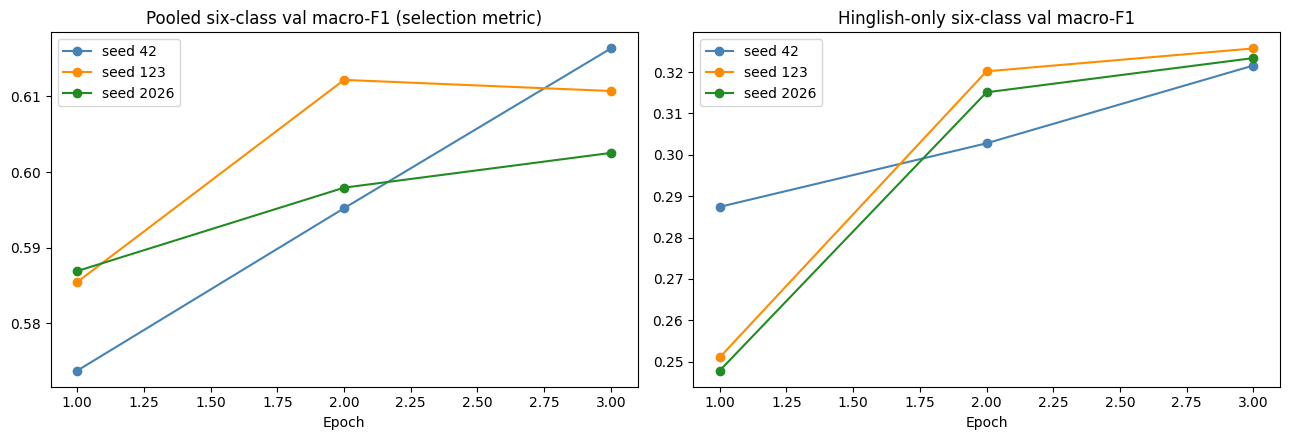

In [33]:
_not_done = [s for s in CFG["seeds"] if not seed_is_complete(s)]
if _not_done:
    print(f"Seeds not complete with the current CFG: {_not_done}. Run Section 20 for them first.")
else:
    rows = []
    for seed in CFG["seeds"]:
        for name in TEST_SETS:
            _, t, lg = read_logits_csv(DIRS["out_logits"] / f"{name}_logits_{_exp_cond}_seed{seed}.csv")
            m = restricted_metrics(t, lg, TEST_ALLOWED[name])
            if name == "goemo_test":
                m["macro_f1_7class"] = float(f1_score(t, lg.argmax(1), average="macro", zero_division=0))
            m.update(seed=seed, test_set=name)
            rows.append(m)
    by_seed = pd.DataFrame(rows)
    by_seed.to_csv(DIRS["out_metrics"] / "metrics_by_seed.csv", index=False)

    metric_cols = ["accuracy", "macro_f1", "macro_f1_core", "macro_f1_strict", "weighted_f1", "ece", "brier", "macro_f1_7class"]
    metric_cols = [c for c in metric_cols if c in by_seed.columns]
    summ = by_seed.groupby("test_set")[metric_cols].agg(["mean", "std"])
    summ.columns = [f"{a}_{b}" for a, b in summ.columns]
    summ = summ.reset_index()
    summ.to_csv(DIRS["out_metrics"] / "summary_by_test_set.csv", index=False)

    print("=" * 70); print(f"RESULTS — Condition {CONDITION}: mean / SD over {len(CFG['seeds'])} seeds"); print("=" * 70)
    with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 160, "display.max_columns", 30):
        for name in TEST_SETS:
            r = summ[summ.test_set == name].iloc[0]
            print(f"\n[{name}]  n={int(by_seed[by_seed.test_set == name].n.iloc[0])}  classes={int(by_seed[by_seed.test_set == name].n_classes.iloc[0])}")
            for c in metric_cols:
                if pd.isna(r[c + '_mean']):
                    continue
                print(f"  {c:<18} {r[c + '_mean']:.4f} ± {r[c + '_std']:.4f}")

    pcs = []
    for name in TEST_SETS:
        sub = by_seed[by_seed.test_set == name]
        for lbl in LABEL_ORDER:
            v = sub[f"f1_{lbl}"]
            pcs.append({"test_set": name, "label": lbl, "support": int(sub[f"support_{lbl}"].iloc[0]),
                        "f1_mean": v.mean(), "f1_sd": v.std()})
    pc = pd.DataFrame(pcs); pc.to_csv(DIRS["out_metrics"] / "per_class_f1_by_test_set.csv", index=False)
    print("\nPer-class F1 (mean over seeds; NaN = class not in that label space):")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 160):
        print(pc.pivot(index="label", columns="test_set", values="f1_mean").reindex(LABEL_ORDER))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for seed, col in zip(CFG["seeds"], ["steelblue", "darkorange", "forestgreen"]):
        h = json.loads((DIRS["out_logs"] / f"training_history_{_exp_cond}_seed{seed}.json").read_text())
        ep = [r["epoch"] for r in h]
        axes[0].plot(ep, [r["val_pooled6_macro_f1"] for r in h], "-o", color=col, label=f"seed {seed}")
        axes[1].plot(ep, [r["val_hi6_macro_f1"] for r in h], "-o", color=col, label=f"seed {seed}")
    axes[0].set_title("Pooled six-class val macro-F1 (selection metric)"); axes[1].set_title("Hinglish-only six-class val macro-F1")
    for a in axes:
        a.set_xlabel("Epoch"); a.legend()
    plt.tight_layout(); plt.savefig(DIRS["out_figures"] / "training_curves_all_seeds.png", dpi=150, bbox_inches="tight"); plt.show()


## Section 21 — Experiment metadata

In [34]:
_seeds_done = [s for s in CFG["seeds"] if seed_is_complete(s)]
final_meta = {
    "experiment_name": CFG["experiment_name"], "condition": CFG["condition_label"], "backbone": CFG["model_name"],
    "model_revision_pinned": CFG["model_revision"], "model_commit_resolved": globals().get("RESOLVED_SHA"),
    "task_data": "GoEmotions-Ekman7 (English, identical to A/C) + EmoSen six-class (Others excluded)",
    "label_order": LABEL_ORDER, "dataset_sha256_goemotions": globals().get("DATASET_SHA256"),
    "dataset_sha256_emosen": globals().get("EMOSEN_SHA256"),
    "train_composition": {"english": int((DF_TRAIN.domain == "en").sum()), "hinglish": int((DF_TRAIN.domain == "hi").sum())},
    "test_sets": {n: {"rows": int(len(d)), "allowed_classes": [ID2LABEL[i] for i in TEST_ALLOWED[n]]} for n, d in TEST_SETS.items()},
    "hyperparameters": {k: str(v) for k, v in CFG.items() if k != "seeds"}, "seeds": CFG["seeds"],
    "seeds_completed": _seeds_done,
    "completion_state": "multi_seed_complete" if sorted(_seeds_done) == sorted(CFG["seeds"]) else "incomplete",
    "software": {"python": sys.version, "pytorch": torch.__version__, "transformers": transformers.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
    "completed_at": datetime.datetime.now().isoformat(),
    "documented_limitations": [
        "Hinglish adaptation data has no Neutral examples; Neutral is excluded from the primary evaluation.",
        "Checkpoint selection uses pooled six-class validation macro-F1, whereas A/C used English 7-class validation macro-F1.",
        "B/D take about 20% more optimiser steps than A/C because the training set is larger.",
        "EmoSen test is the same source as the Hinglish training data (in-domain for B/D); hinemo_test is the held-out check.",
        "EmoSen test has only 13 Fear and 7 Surprise examples: per-class and six-class macro-F1 are noisy; core-class macro-F1 (`macro_f1_core`; 3 classes on HinEmo-9) is reported as a sensitivity.",
    ],
}
with open(DIRS["out_metrics"] / "experiment_metadata.json", "w") as f:
    json.dump(final_meta, f, indent=2)
print(f"Metadata saved. Completion state: {final_meta['completion_state']}  seeds: {_seeds_done}")


Metadata saved. Completion state: multi_seed_complete  seeds: [42, 123, 2026]


## Section 24 — Save Condition C outputs

Copies only this condition's folders (checkpoints, outputs, config) to Drive, so Condition A's saved files are never touched. The GoEmotions data is public, so Drive is fine here. Checkpoints are about 1 GB per seed; set `SAVE_MODELS_TO_DRIVE = False` to skip them. A small ZIP of outputs and config is also created for download.


In [35]:
import shutil
SAVE_MODELS_TO_DRIVE = True
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    dest_root = Path("/content/drive/MyDrive/Beyond-Words")
    to_copy = [PROJECT_ROOT / "outputs" / TAG]
    if SAVE_MODELS_TO_DRIVE:
        to_copy.append(PROJECT_ROOT / "models" / TAG)      # checkpoints contain no EmoSen text
    for src in to_copy:
        dst = dest_root / src.relative_to(PROJECT_ROOT)
        shutil.copytree(src, dst, dirs_exist_ok=True); print("Copied:", src, "->", dst)
    (dest_root / "configs").mkdir(parents=True, exist_ok=True)
    shutil.copy2(config_path, dest_root / "configs" / config_path.name)
    _stage = Path("/content/bd_export"); shutil.rmtree(_stage, ignore_errors=True)
    shutil.copytree(PROJECT_ROOT / "outputs" / TAG, _stage / "outputs" / TAG)
    (_stage / "configs").mkdir(parents=True, exist_ok=True); shutil.copy2(config_path, _stage / "configs" / config_path.name)
    shutil.make_archive(f"/content/Beyond-Words-{TAG}-outputs", "zip", _stage)
    files.download(f"/content/Beyond-Words-{TAG}-outputs.zip")
else:
    print("Not in Colab: outputs are on local disk under", PROJECT_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied: /content/Beyond-Words/outputs/hinglish_adapt_condD -> /content/drive/MyDrive/Beyond-Words/outputs/hinglish_adapt_condD
Copied: /content/Beyond-Words/models/hinglish_adapt_condD -> /content/drive/MyDrive/Beyond-Words/models/hinglish_adapt_condD


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>